# CPE312 (2569) DS Capstone — พยากรณ์ผู้ป่วยไข้หวัดใหญ่รายเขต กทม.

**SDG 3** สุขภาพและความเป็นอยู่ที่ดี | **ชื่อกลุ่ม:** `Super_Chicken`

**โจทย์:** พยากรณ์จำนวนผู้ป่วยไข้หวัดใหญ่รายเขตของ กทม. ล่วงหน้า 1 สัปดาห์ เพื่อให้สำนักอนามัยตัดสินใจส่งทีมคัดกรองและจัดสรรยาต้านไวรัสไปยังเขตที่คาดว่าผู้ป่วยจะเพิ่มขึ้น

| สมาชิก | รหัสนิสิต | บทบาท |
|---|---|---|
| `ภูผา พรมน้อย` |67109010298| ผู้สร้างโมเดล & ผู้ตรวจคุณภาพ |
| `ธนิษฐา ศิลปวิสุทธิ์` |67109010391| ผู้ดูแลข้อมูล |
| `พนัชกร ภูทอง` |67109010395| ผู้เล่าเรื่อง |


**วิธีใช้:** รันทุก cell ตามลำดับจากบนลงล่าง (Runtime → Run all) ตัวเลขทุกตัวบนโปสเตอร์ต้องตรงกับผลใน notebook นี้

# R1 — โจทย์ที่สมเหตุสมผล (Business Understanding)

| # | เกณฑ์ | คำตอบของกลุ่ม |
|---|---|---|
| 1 | ใครใช้ผลพยากรณ์ / ตัดสินใจอะไร | สำนักอนามัย กทม. ใช้ผลพยากรณ์เพื่อตัดสินใจส่งทีมคัดกรองและจัดสรรยาต้านไวรัสไปยังเขตที่คาดว่าผู้ป่วยจะเพิ่มขึ้น |
| 2 | ทำนายเมื่อไร / ข้อมูลที่มี | ทำนายทุกวันจันทร์ โดยใช้ข้อมูลจำนวนผู้ป่วยย้อนหลังถึงวันอาทิตย์ที่ผ่านมาเท่านั้น เพื่อทำนายจำนวนผู้ป่วยของสัปดาห์ถัดไป (ไม่ใช้ข้อมูลของสัปดาห์ที่ทำนาย เพื่อกัน data leakage) |
| 3 | 1 แถว คืออะไร | 1 เขต × 1 สัปดาห์ |
| 4 | เป้าหมาย | จำนวนผู้ป่วยไข้หวัดใหญ่ที่รายงานในเขตนั้น ในสัปดาห์ถัดไป (จันทร์–อาทิตย์) นับตามวันที่เริ่มป่วย `[ยืนยันว่า "เขต" คือที่อยู่ผู้ป่วยหรือสถานที่รักษา]` |
| 5 | ความผิดพลาดที่แพงกว่า | ทำนายต่ำกว่าจริงเสียหายกว่า เพราะทีมและยาจะไม่เพียงพอสำหรับผู้ป่วย (เตรียมเกินยังดีกว่าขาด) จึงใช้ MAE เป็นตัววัดหลัก และดูสัดส่วนครั้งที่ทำนายต่ำกว่าจริงควบคู่ |

**ตัววัด:** MAE (ราย/เขต/สัปดาห์) · สัดส่วนครั้งที่ทำนายต่ำกว่าจริง · Top-10 hit rate (ใน 10 เขตที่โมเดลทำนายสูงสุด มีกี่เขตที่อยู่ใน 10 เขตสูงสุดจริง)

## 0. ตั้งค่าและโหลดข้อมูล

ตั้ง `USE_DRIVE = True` เพื่ออ่านไฟล์จาก Google Drive (วางไฟล์ข้อมูลทั้ง 3 ไฟล์ไว้ที่ `MyDrive/CPE312_DataSci/data/`) หรือ `False` เพื่ออัปโหลดตรงเข้า Colab (หายเมื่อ session หมดอายุ; ต้องอัปโหลดทั้ง 3 ไฟล์ในครั้งเดียว)

In [5]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

USE_DRIVE = True
# ข้อมูล 3 ไฟล์ ต่อกันเป็นช่วงเวลาเดียวต่อเนื่อง (วางทุกไฟล์ไว้ในโฟลเดอร์เดียวกัน)
FILES = [('2025 มิ.ย.–ธ.ค.', '5_2025_sent_2025-12-316-12.csv'),
         ('2026 ม.ค.–มิ.ย.', '5_2026_1-6.csv'),
         ('2026 ก.ค.–ต.ค.', '5_2026_7-10.csv')]

if USE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_DIR = '/content/drive/MyDrive/CPE312_DataSci/data/'
else:
    from google.colab import files
    files.upload()
    DATA_DIR = './'

START, END = pd.Timestamp('2025-06-02'), pd.Timestamp('2026-10-25')   # 73 สัปดาห์เต็ม จันทร์–อาทิตย์
EXPECT_DISTRICTS, EXPECT_WEEKS = 50, 73                               # กทม. มี 50 เขต
AGE_MAX = 110
DUP_POLICY = 'keep'  # 'keep' = เก็บแถวซ้ำ | 'drop' = ลบแถวซ้ำ (เหตุผลดูหัวข้อ 4)
problems = []   # (ปัญหา, จำนวนที่พบ, วิธีจัดการ) -> ตารางโปสเตอร์

# ---- การออกแบบ train/test: ล็อกไว้ก่อนรันโมเดล (ดูหัวข้อ "วิธีแบ่ง train/test") ----
TEST_START = pd.Timestamp('2026-07-06')                               # test = ก.ค.–ต.ค. 2026 (ฤดูที่ 2)
SUSPECT_WEEKS = [pd.Timestamp('2025-12-22'), pd.Timestamp('2025-12-29')]   # รายงานไม่ครบปลายไฟล์ 2025 (ดูหัวข้อ 3.1)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### ตั้งค่ากราฟ (ฟอนต์ไทย + สไตล์)
รันก่อนส่วนที่ต้องวาดกราฟ ใช้ในหัวข้อ 3.1 และ R3–R5

In [6]:
# ---------- ตั้งค่ากราฟ: ฟอนต์ไทย + สไตล์ ----------
import matplotlib.font_manager as fm
import shutil, subprocess

def find_thai_font():
    keys = ['loma', 'garuda', 'norasi', 'kinnari', 'waree', 'laksaman', 'sarabun', 'notosansthai']
    for f in fm.findSystemFonts():
        if any(k in os.path.basename(f).lower() for k in keys):
            return f
    return None

font_path = find_thai_font()
if font_path is None and shutil.which('apt-get'):      # Colab: ติดตั้งฟอนต์ไทย (ประมาณครึ่งนาที)
    subprocess.run(['apt-get', '-qq', 'install', '-y', 'fonts-thai-tlwg'], check=False, capture_output=True)
    font_path = find_thai_font()

TH = font_path is not None
if TH:
    fm.fontManager.addfont(font_path)
    plt.rcParams['font.family'] = fm.FontProperties(fname=font_path).get_name()
    print('ใช้ฟอนต์ไทย:', plt.rcParams['font.family'])
else:
    print('ไม่พบฟอนต์ไทย: ใช้ข้อความภาษาอังกฤษบนกราฟ (ชื่อเขตอาจเป็นสี่เหลี่ยม)')

def T(th, en):
    return th if TH else en

INK, INK2, MUTED = '#0b0b0b', '#52514e', '#898781'
GRID, AXIS, SURFACE = '#e1e0d9', '#c3c2b7', '#fcfcfb'
BLUE, GRAY = '#2a78d6', '#c3c2b7'
plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'text.color': INK, 'axes.labelcolor': INK2, 'xtick.color': MUTED, 'ytick.color': MUTED,
    'axes.edgecolor': AXIS, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 1, 'axes.axisbelow': True,
    'axes.unicode_minus': False, 'font.size': 11, 'axes.titlesize': 13,
    'axes.titleweight': 'normal', 'axes.titlelocation': 'left'})


ใช้ฟอนต์ไทย: ['Loma']


**ผลที่ควรได้ (ในเซลล์หัวข้อ 1):** ตารางจำนวนแถวต่อไฟล์ และไข้หวัดใหญ่รวม 3 ไฟล์ = `209,402` แถว (2025: 114,124 · ม.ค.–มิ.ย. 2026: 28,870 · ก.ค.–ต.ค. 2026: 66,408)

# R2 — ข้อมูลที่ตรวจสอบได้ (Data Understanding / Preparation)

**แหล่งข้อมูล:** `[https://data.bangkok.go.th/dataset/5_desease]` · **license:** ไม่ระบุ — หน้าชุดข้อมูลแสดง “License not specified” (ตรวจเมื่อ 11 พ.ย. 2026) กลุ่มจึงใช้ข้อมูลเพื่อการศึกษาในรายวิชานี้ อ้างอิงแหล่งที่มา และไม่เผยแพร่ข้อมูลรายแถวต่อ · **ขนาด:** 3 ไฟล์ ช่วง 1 มิ.ย. 2025 – 31 ต.ค. 2026 (ไข้หวัดใหญ่ 209,402 แถว) · ทุกแถวเป็น กทม.


## 1. โหลดข้อมูล 3 ไฟล์และกรองโรค
อ่านทุกคอลัมน์เป็นข้อความ (`dtype=str`) เพื่อไม่ให้ pandas เดาชนิดผิด (คอลัมน์อายุมีชนิดปนกัน) ลบแถวที่ว่างทุกคอลัมน์ (พบในไฟล์ ม.ค.–มิ.ย. 2026) แล้วต่อไฟล์เข้าด้วยกัน

In [7]:
frames, file_rows = [], []
for tag, fname in FILES:
    x = pd.read_csv(DATA_DIR + fname, dtype=str)
    n_all = len(x)
    n_blank = int(x.isna().all(axis=1).sum())          # แถวที่ว่างทุกคอลัมน์
    x = x.dropna(how='all').copy()
    x['ชื่อกลุ่มโรค'] = x['ชื่อกลุ่มโรค'].str.strip()
    x['src'] = tag
    frames.append(x)
    file_rows.append((tag, n_all, n_blank, len(x), int((x['ชื่อกลุ่มโรค'] == 'ไข้หวัดใหญ่').sum())))
print(pd.DataFrame(file_rows, columns=['ไฟล์', 'แถวในไฟล์', 'แถวว่างทั้งแถว', 'แถวข้อมูลจริง', 'ไข้หวัดใหญ่']).to_string(index=False))
assert all(list(f.columns) == list(frames[0].columns) for f in frames), 'คอลัมน์ของ 3 ไฟล์ไม่ตรงกัน'

raw = pd.concat(frames, ignore_index=True)
RAW_COLS = [c for c in raw.columns if c != 'src']
N_BLANK = sum(r[2] for r in file_rows)
problems.append(('แถวว่างทั้งแถว (ไฟล์ ม.ค.–มิ.ย. 2026)', N_BLANK, 'ลบออกก่อนใช้งาน เพราะไม่มีข้อมูลใดๆ'))

flu = raw[raw['ชื่อกลุ่มโรค'] == 'ไข้หวัดใหญ่'].copy()
N_FLU = len(flu)
print('\nไข้หวัดใหญ่รวม 3 ไฟล์:', N_FLU, '(คาด 209,402)', '✓' if N_FLU == 209402 else '✗ ตรวจสอบ')


           ไฟล์  แถวในไฟล์  แถวว่างทั้งแถว  แถวข้อมูลจริง  ไข้หวัดใหญ่
2025 มิ.ย.–ธ.ค.     234081               0         234081       114124
2026 ม.ค.–มิ.ย.     807977          692832         115145        28870
 2026 ก.ค.–ต.ค.     163632               0         163632        66408

ไข้หวัดใหญ่รวม 3 ไฟล์: 209402 (คาด 209,402) ✓


## 2. แปลงวันที่ + สร้างสัปดาห์ (จันทร์–อาทิตย์)

In [8]:
flu['date'] = pd.to_datetime(flu['วันที่เริ่มป่วย'].str.strip(), format='%d/%m/%Y', errors='coerce')
n_bad_date = int(flu['date'].isna().sum())
print('แปลงวันที่ไม่ได้:', n_bad_date)
print(flu.groupby('src')['date'].agg(['min', 'max']).to_string())      # ต้องต่อกันเป็นช่วงเดียว ปี ค.ศ. ทุกไฟล์

# week_start = วันจันทร์ของสัปดาห์นั้น (dayofweek: จันทร์=0 ... อาทิตย์=6)
flu['week_start'] = flu['date'] - pd.to_timedelta(flu['date'].dt.dayofweek, unit='D')


แปลงวันที่ไม่ได้: 0
                       min        max
src                                  
2025 มิ.ย.–ธ.ค. 2025-06-01 2025-12-30
2026 ก.ค.–ต.ค.  2026-07-01 2026-10-31
2026 ม.ค.–มิ.ย. 2026-01-01 2026-06-30


## 3. เก็บเฉพาะ 2 มิ.ย. 2025 – 25 ต.ค. 2026 (73 สัปดาห์เต็ม)

In [9]:
n_before = int((flu['date'] < START).sum())
n_after  = int((flu['date'] > END).sum())
in_range = flu['date'].between(START, END)
d = flu[in_range].copy()

print(f'ก่อน {START.date()} (สัปดาห์แรกมีแค่ 1 มิ.ย. 2025): {n_before} แถว')
print(f'หลัง {END.date()} (26–31 ต.ค. 2026 สัปดาห์ไม่เต็ม และรายงานยังไม่ครบ): {n_after} แถว')
print(f'วันที่แปลงไม่ได้: {n_bad_date} แถว')
print('คงเหลือในช่วง:', len(d), '| ตรวจ:', N_FLU, '=', len(d), '+', n_before + n_after + n_bad_date)
assert len(d) + n_before + n_after + n_bad_date == N_FLU

problems.append(('วันที่อยู่นอกช่วง 2 มิ.ย. 2025–25 ต.ค. 2026 (1 มิ.ย. 2025 และ 26–31 ต.ค. 2026)', n_before + n_after,
                 'ตัดออก เพื่อให้ทุกสัปดาห์ครบ 7 วัน (จันทร์–อาทิตย์)'))
problems.append(('วันที่เริ่มป่วยแปลงไม่ได้', n_bad_date, 'ตัดออก (ไม่มีสัปดาห์ให้จัดกลุ่ม)'))


ก่อน 2025-06-02 (สัปดาห์แรกมีแค่ 1 มิ.ย. 2025): 142 แถว
หลัง 2026-10-25 (26–31 ต.ค. 2026 สัปดาห์ไม่เต็ม และรายงานยังไม่ครบ): 2621 แถว
วันที่แปลงไม่ได้: 0 แถว
คงเหลือในช่วง: 206639 | ตรวจ: 209402 = 206639 + 2763


### 3.1 รายงานล่าช้า (reporting lag) ที่ปลายไฟล์ — ตรวจด้วยข้อมูลรายวัน

แต่ละไฟล์ถูกดึงในเวลาต่างกัน ผู้ป่วยที่เพิ่งเริ่มป่วยมักถูกรายงานเข้าระบบช้ากว่า จำนวนรายวันท้ายไฟล์จึงต่ำกว่าจริง ไฟล์ 2025 ถูกดึงราว 31 ธ.ค. ต่างจากไฟล์ 2026 ที่ถูกดึงทีหลัง
ตรวจโดยดูว่าจำนวนรายวัน **ลดฮวบก่อนรอยต่อ แต่กลับขึ้นทันทีหลังรอยต่อ** หรือไม่ (ถ้าเป็นการลดลงจริง ค่าหลังรอยต่อควรต่อเนื่อง)

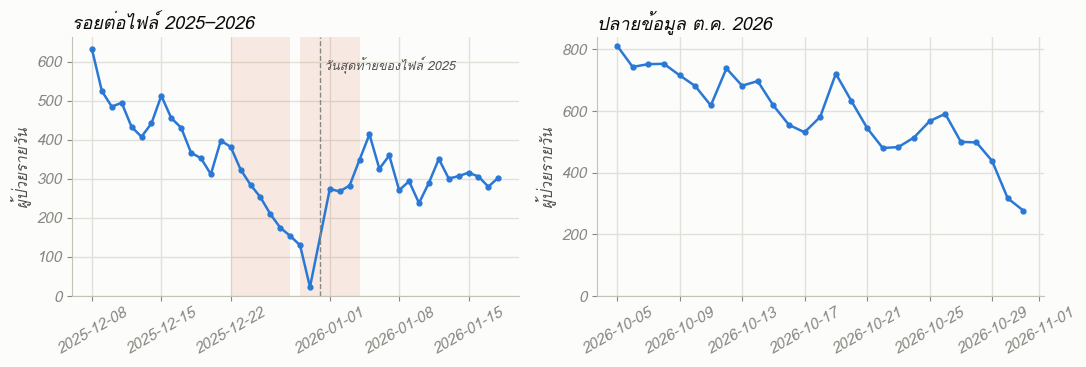

รายวัน 22 ธ.ค. 2025 – 4 ม.ค. 2026 (31 ธ.ค. ไม่มีรายงานเลย):
2025-12-22    382
2025-12-23    324
2025-12-24    285
2025-12-25    253
2025-12-26    210
2025-12-27    175
2025-12-28    154
2025-12-29    130
2025-12-30     23
2025-12-31      0
2026-01-01    274
2026-01-02    268
2026-01-03    283
2026-01-04    349
Freq: D

รายวัน 24–31 ต.ค. 2026:
date
2026-10-24    514
2026-10-25    567
2026-10-26    591
2026-10-27    500
2026-10-28    498
2026-10-29    438
2026-10-30    317
2026-10-31    277

ผู้ป่วยในสัปดาห์ที่ไม่น่าเชื่อถือ ['2025-12-22', '2025-12-29']: 3110 ราย


In [10]:
daily = flu['date'].value_counts().sort_index()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, (lo, hi, ttl) in zip(axes, [('2025-12-08', '2026-01-18', T('รอยต่อไฟล์ 2025–2026', 'File boundary 2025 to 2026')),
                                    ('2026-10-05', '2026-10-31', T('ปลายข้อมูล ต.ค. 2026', 'End of data, Oct 2026'))]):
    s = daily[lo:hi]
    ax.plot(s.index, s.values, color=BLUE, lw=1.8, marker='o', ms=3.5)
    ax.set_title(ttl); ax.set_ylabel(T('ผู้ป่วยรายวัน', 'cases per day'))
    ax.set_ylim(0)
    ax.tick_params(axis='x', labelrotation=30)
axes[0].axvline(pd.Timestamp('2025-12-31'), color=MUTED, lw=1, ls='--')
axes[0].text(pd.Timestamp('2025-12-31'), daily['2025-12-08':'2026-01-18'].max() * 0.97, T(' วันสุดท้ายของไฟล์ 2025', ' last day of 2025 file'), color=INK2, fontsize=9, va='top')
for w in SUSPECT_WEEKS:
    axes[0].axvspan(w, w + pd.Timedelta(days=6), color='#d9622b', alpha=0.12, lw=0)
plt.tight_layout(); plt.show()

print('รายวัน 22 ธ.ค. 2025 – 4 ม.ค. 2026 (31 ธ.ค. ไม่มีรายงานเลย):')
print(daily['2025-12-22':'2026-01-04'].reindex(pd.date_range('2025-12-22', '2026-01-04'), fill_value=0).astype(int).to_string())
print('\nรายวัน 24–31 ต.ค. 2026:'); print(daily['2026-10-24':'2026-10-31'].astype(int).to_string())

SUSPECT_N = int(d['week_start'].isin(SUSPECT_WEEKS).sum())
print(f'\nผู้ป่วยในสัปดาห์ที่ไม่น่าเชื่อถือ {[w.date().isoformat() for w in SUSPECT_WEEKS]}: {SUSPECT_N} ราย')
problems.append(('รายงานล่าช้าปลายไฟล์ 2025 (สัปดาห์ 22 และ 29 ธ.ค. 2025): 22–28 ธ.ค. ลดจาก 382 เหลือ 154 ราย/วัน, 30 ธ.ค. เหลือ 23, 31 ธ.ค. ไม่มี แต่ 1 ม.ค. กลับมา 274',
                 SUSPECT_N, 'เก็บไว้ในตาราง (ผลรวมยังตรวจได้) แต่ไม่ใช้เป็นเป้าหมายหรือ lag ของโมเดล (ตัดเป้าหมาย 22 ธ.ค.–26 ม.ค. รวม 6 สัปดาห์)'))


## 4. แถวซ้ำเต็มแถว (ห้ามลบเงียบๆ)
ไฟล์นี้ **ไม่มีรหัสผู้ป่วย** แถวที่ซ้ำกันทุกคอลัมน์จึงอาจเป็นรายงานซ้ำ *หรือ* ผู้ป่วยคนละคนที่ข้อมูลตรงกัน (เช่น เพศ อายุ เขต ตำบล วันที่ โรงพยาบาลเดียวกัน) แยกไม่ได้จากข้อมูลเอง
ค่าเริ่มต้นคือ **เก็บไว้** (`DUP_POLICY='keep'`) เพื่อไม่ให้จำนวนผู้ป่วยต่ำกว่าจริง และทำให้ `sum(cases)` = จำนวนแถวในช่วงวันที่ ปรับที่เซลล์ตั้งค่าได้ถ้ากลุ่มตกลงเป็นอย่างอื่น

In [11]:
dup_extra  = int(d.duplicated(subset=RAW_COLS, keep='first').sum())   # แถวที่ "เกิน" ซ้ำ
dup_in_grp = int(d.duplicated(subset=RAW_COLS, keep=False).sum())     # แถวทั้งหมดที่อยู่ในกลุ่มซ้ำ
print(f'แถวซ้ำเต็มแถว: เกิน {dup_extra} แถว (รวมทุกแถวที่อยู่ในกลุ่มซ้ำ {dup_in_grp}) = {dup_extra/len(d):.2%}')

if DUP_POLICY == 'drop':
    d = d.drop_duplicates(subset=RAW_COLS, keep='first').copy()
    handling = 'ลบแถวซ้ำ เก็บแถวแรกไว้'
else:
    handling = ('เก็บไว้ทั้งหมด: ไฟล์ไม่มีรหัสผู้ป่วย แยกรายงานซ้ำออกจากผู้ป่วยคนละคนที่ข้อมูลตรงกันไม่ได้ '
                'และการลบอาจทำให้จำนวนผู้ป่วยต่ำกว่าจริง')
problems.append(('แถวซ้ำเต็มแถว (ทุกคอลัมน์เหมือนกัน)', dup_extra, handling))
print('นโยบาย:', DUP_POLICY, '| แถวที่ใช้ต่อ:', len(d))

แถวซ้ำเต็มแถว: เกิน 423 แถว (รวมทุกแถวที่อยู่ในกลุ่มซ้ำ 819) = 0.20%
นโยบาย: keep | แถวที่ใช้ต่อ: 206639


## 5. ทำความสะอาด

In [12]:
# --- อายุ (ใช้คอลัมน์ 'อายุ (เต็ม) ปี') ---
age_raw = d['อายุ (เต็ม) ปี'].str.strip()
age = pd.to_numeric(age_raw, errors='coerce')
n_age_blank  = int(age_raw.isna().sum())
n_age_nonnum = int((age.isna() & age_raw.notna()).sum())
n_age_over   = int((age > AGE_MAX).sum())
n_age_neg    = int((age < 0).sum())
d['age'] = age.mask((age > AGE_MAX) | (age < 0))
print(f'อายุว่าง {n_age_blank} | แปลงไม่ได้ {n_age_nonnum} | เกิน {AGE_MAX} {n_age_over} | ติดลบ {n_age_neg} | NaN รวมหลังทำความสะอาด {int(d["age"].isna().sum())}')
if n_age_blank:  problems.append(('อายุว่าง', n_age_blank, 'เป็น NaN (นับใน cases แต่ไม่อยู่ในกลุ่มอายุใด)'))
problems.append((f'อายุแปลงเป็นตัวเลขไม่ได้', n_age_nonnum, 'เป็น NaN'))
problems.append((f'อายุผิดปกติ (>{AGE_MAX} หรือ <0)', n_age_over + n_age_neg, 'เป็น NaN'))

# --- เพศ / สภาพผู้ป่วย / ประเภทผู้ป่วย: "0" -> NaN ---
for col in ['เพศ', 'สภาพผู้ป่วย', 'ประเภทผู้ป่วย']:
    d[col] = d[col].str.strip()
    n0 = int((d[col] == '0').sum())
    d[col] = d[col].replace('0', np.nan)
    print(f'{col}: "0" = {n0}')
    problems.append((f'{col} เป็น "0" (รหัสไม่มีข้อมูล)', n0, 'เปลี่ยนเป็น NaN'))

# --- ชื่อเขต ---
d['district'] = d['อำเภอ/เขต'].str.strip()
n_space = int((d['อำเภอ/เขต'] != d['district']).sum())
n_dist_na = int(d['district'].isna().sum())
print(f'ชื่อเขตมีช่องว่างหน้าหลัง: {n_space} | เขตว่าง: {n_dist_na}')
problems.append(('ชื่อเขตมีช่องว่างหน้า/หลัง', n_space, 'ตัดช่องว่าง (strip)'))
# --- ชื่อเขตสะกดต่างกัน: บางแถวมีคำนำหน้า "เขต" (เช่น "เขตบางพลัด") ซึ่งคือ "บางพลัด" เดิม ---
d['district_norm'] = d['district'].str.replace(r'^เขต', '', regex=True).str.strip()
n_prefix = int((d['district'] != d['district_norm']).sum())
print(f'ชื่อเขตมีคำนำหน้า "เขต": {n_prefix} แถว', d.loc[d['district'] != d['district_norm'], 'district'].unique())
d['district'] = d['district_norm']
problems.append(('ชื่อเขตสะกดต่างกัน (มีคำนำหน้า "เขต" เช่น เขตบางพลัด)', n_prefix, 'ตัดคำนำหน้า "เขต" ให้ตรงกับชื่อเขตมาตรฐาน (รวมเป็น 50 เขต)'))
assert n_dist_na == 0, 'มีแถวที่ไม่มีชื่อเขต: ต้องตัดสินใจก่อน (จะหายไปตอน groupby)'

print('\nจังหวัด:'); print(d['จังหวัด'].value_counts(dropna=False))
print('\nประเภทผู้ป่วย:'); print(d['ประเภทผู้ป่วย'].value_counts(dropna=False))

อายุว่าง 1 | แปลงไม่ได้ 0 | เกิน 110 7 | ติดลบ 0 | NaN รวมหลังทำความสะอาด 8
เพศ: "0" = 26
สภาพผู้ป่วย: "0" = 23
ประเภทผู้ป่วย: "0" = 1
ชื่อเขตมีช่องว่างหน้าหลัง: 0 | เขตว่าง: 0
ชื่อเขตมีคำนำหน้า "เขต": 1 แถว ['เขตบางพลัด']

จังหวัด:
จังหวัด
กรุงเทพมหานคร    206639
Name: count, dtype: int64

ประเภทผู้ป่วย:
ประเภทผู้ป่วย
ผู้ป่วยนอก      172439
ผู้ป่วยใน        34143
ค้นพบในชุมชน        56
NaN                  1
Name: count, dtype: int64


## 6. ตรวจรายชื่อเขต (ต้องได้ 50)

In [13]:
districts = sorted(d['district'].unique())
print(len(districts), 'เขต')
print(districts)
if len(districts) != EXPECT_DISTRICTS:
    print(f'⚠ ได้ {len(districts)} ไม่ใช่ {EXPECT_DISTRICTS}: ดูรายชื่อด้านบน (สะกดต่างกัน? มีค่าแปลก เช่น "ไม่ทราบ"/เขตนอก กทม.?) แล้วแจ้งในกลุ่ม')

50 เขต
['คลองสาน', 'คลองสามวา', 'คลองเตย', 'คันนายาว', 'จตุจักร', 'จอมทอง', 'ดอนเมือง', 'ดินแดง', 'ดุสิต', 'ตลิ่งชัน', 'ทวีวัฒนา', 'ทุ่งครุ', 'ธนบุรี', 'บางกอกน้อย', 'บางกอกใหญ่', 'บางกะปิ', 'บางขุนเทียน', 'บางคอแหลม', 'บางซื่อ', 'บางนา', 'บางบอน', 'บางพลัด', 'บางรัก', 'บางเขน', 'บางแค', 'บึงกุ่ม', 'ปทุมวัน', 'ประเวศ', 'ป้อมปราบศัตรูพ่าย', 'พญาไท', 'พระนคร', 'พระโขนง', 'ภาษีเจริญ', 'มีนบุรี', 'ยานนาวา', 'ราชเทวี', 'ราษฎร์บูรณะ', 'ลาดกระบัง', 'ลาดพร้าว', 'วังทองหลาง', 'วัฒนา', 'สวนหลวง', 'สะพานสูง', 'สัมพันธวงศ์', 'สาทร', 'สายไหม', 'หนองจอก', 'หนองแขม', 'หลักสี่', 'ห้วยขวาง']


## 7. Aggregate เป็นเขต × สัปดาห์ และเติมตารางเต็ม (ไม่มีผู้ป่วย = 0)

In [14]:
AGE_LABELS = ['age_0_4', 'age_5_14', 'age_15_24', 'age_25_59', 'age_60plus']
d['age_group'] = pd.cut(d['age'], bins=[0, 5, 15, 25, 60, np.inf], right=False, labels=AGE_LABELS)  # [0,5) [5,15) ...

d['inpatient_cases'] = (d['ประเภทผู้ป่วย'] == 'ผู้ป่วยใน').astype(int)
for g in AGE_LABELS:
    d[g] = (d['age_group'] == g).astype(int)
d['age_nan'] = d['age'].isna().astype(int)
d['cases'] = 1

agg = d.groupby(['district', 'week_start'])[['cases', 'inpatient_cases'] + AGE_LABELS + ['age_nan']].sum()

weeks = pd.date_range(START, periods=EXPECT_WEEKS, freq='7D')
assert weeks[-1] + pd.Timedelta(days=6) == END, 'สัปดาห์สุดท้ายต้องจบที่ 25 ต.ค. 2026'
grid = pd.MultiIndex.from_product([districts, weeks], names=['district', 'week_start'])
full = agg.reindex(grid, fill_value=0).reset_index()
print(full.shape)
full.head()

(3650, 10)


,district,week_start,cases,inpatient_cases,age_0_4,age_5_14,age_15_24,age_25_59,age_60plus,age_nan
0,คลองสาน,2025-06-02,19,2,0,5,2,7,5,0
1,คลองสาน,2025-06-09,11,0,0,4,0,7,0,0
2,คลองสาน,2025-06-16,3,2,0,2,0,0,1,0
3,คลองสาน,2025-06-23,9,0,0,3,2,3,1,0
4,คลองสาน,2025-06-30,25,1,2,4,4,7,8,0


## 8. ตรวจก่อนส่ง (ต้องผ่านทุกข้อ)

In [15]:
n_rows_expected = len(districts) * EXPECT_WEEKS
print('1) จำนวนแถว', len(full), '(คาด', n_rows_expected, ')')
assert len(full) == n_rows_expected
if len(districts) == EXPECT_DISTRICTS: assert len(full) == 3650
assert not full.duplicated(['district', 'week_start']).any(), 'มีคู่เขต-สัปดาห์ซ้ำ'

print('2) sum(cases) =', full['cases'].sum(), '| แถวที่ใช้ในช่วงวันที่ =', len(d))
assert full['cases'].sum() == len(d)
expl = N_FLU - full['cases'].sum()
print(f'   ส่วนต่างจากไข้หวัดใหญ่ทั้งไฟล์ {expl} = นอกช่วง {n_before + n_after} + วันที่เสีย {n_bad_date}' +
      (f' + ลบซ้ำ {dup_extra}' if DUP_POLICY == 'drop' else ''))

print('3) ติดลบ/NaN:', int((full['cases'] < 0).sum()), '/', int(full['cases'].isna().sum()))
assert (full['cases'] >= 0).all() and full['cases'].notna().all()

print('4) กลุ่มอายุ + age NaN = cases')
assert (full[AGE_LABELS].sum(axis=1) + full['age_nan'] == full['cases']).all()
assert (full['inpatient_cases'] <= full['cases']).all()
print('ผ่านครบ ✓')

print(f'\nสัดส่วนเขต-สัปดาห์ที่ cases=0: {(full.cases==0).mean():.2%} | cases เฉลี่ย {full.cases.mean():.1f} ราย/เขต/สัปดาห์')

1) จำนวนแถว 3650 (คาด 3650 )
2) sum(cases) = 206639 | แถวที่ใช้ในช่วงวันที่ = 206639
   ส่วนต่างจากไข้หวัดใหญ่ทั้งไฟล์ 2763 = นอกช่วง 2763 + วันที่เสีย 0
3) ติดลบ/NaN: 0 / 0
4) กลุ่มอายุ + age NaN = cases
ผ่านครบ ✓

สัดส่วนเขต-สัปดาห์ที่ cases=0: 0.08% | cases เฉลี่ย 56.6 ราย/เขต/สัปดาห์


## 9. บันทึกไฟล์ + ตารางสรุปปัญหา

In [16]:
out = full[['district', 'week_start', 'cases', 'inpatient_cases'] + AGE_LABELS].copy()
out['week_start'] = out['week_start'].dt.strftime('%Y-%m-%d')
out.to_csv('flu_district_week_2025_2026.csv', index=False, encoding='utf-8-sig')

summary = pd.DataFrame(problems, columns=['ปัญหา', 'จำนวนที่พบ', 'วิธีจัดการ'])
summary.to_csv('r2_problem_summary.csv', index=False, encoding='utf-8-sig')
display(summary)

try:
    from google.colab import files
    files.download('flu_district_week_2025_2026.csv'); files.download('r2_problem_summary.csv')
except ImportError:
    pass

,ปัญหา,จำนวนที่พบ,วิธีจัดการ
0,แถวว่างทั้งแถว (ไฟล์ ม.ค.–มิ.ย. 2026),692832,ลบออกก่อนใช้งาน เพราะไม่มีข้อมูลใดๆ
1,วันที่อยู่นอกช่วง 2 มิ.ย. 2025–25 ต.ค. 2026 (1...,2763,ตัดออก เพื่อให้ทุกสัปดาห์ครบ 7 วัน (จันทร์–อาท...
2,วันที่เริ่มป่วยแปลงไม่ได้,0,ตัดออก (ไม่มีสัปดาห์ให้จัดกลุ่ม)
3,รายงานล่าช้าปลายไฟล์ 2025 (สัปดาห์ 22 และ 29 ธ...,3110,เก็บไว้ในตาราง (ผลรวมยังตรวจได้) แต่ไม่ใช้เป็น...
4,แถวซ้ำเต็มแถว (ทุกคอลัมน์เหมือนกัน),423,เก็บไว้ทั้งหมด: ไฟล์ไม่มีรหัสผู้ป่วย แยกรายงาน...
5,อายุว่าง,1,เป็น NaN (นับใน cases แต่ไม่อยู่ในกลุ่มอายุใด)
6,อายุแปลงเป็นตัวเลขไม่ได้,0,เป็น NaN
7,อายุผิดปกติ (>110 หรือ <0),7,เป็น NaN
8,"เพศ เป็น ""0"" (รหัสไม่มีข้อมูล)",26,เปลี่ยนเป็น NaN
9,"สภาพผู้ป่วย เป็น ""0"" (รหัสไม่มีข้อมูล)",23,เปลี่ยนเป็น NaN


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### ตรวจเพิ่ม: คอลัมน์ อำเภอ/เขต คือที่อยู่ผู้ป่วยหรือที่ตั้งสถานพยาบาล?

ถ้าเป็นที่ตั้งสถานพยาบาล ผู้ป่วยของสถานพยาบาลหนึ่งควรอยู่ในเขตเดียวหรือไม่กี่เขต แต่ถ้าเป็นที่อยู่ผู้ป่วย ผู้ป่วยของสถานพยาบาลเดียวกันจะมาจากหลายเขต

In [17]:
hosp = d.groupby('สถานที่รักษา')['district'].agg(
    n_cases='size', n_districts='nunique',
    top_share=lambda s: s.value_counts(normalize=True).iloc[0])
big = hosp[hosp['n_cases'] >= 200]
print('สถานที่รักษาที่มีผู้ป่วย >= 200 ราย:', len(big), 'แห่ง')
print('จำนวนเขตต่อสถานที่รักษา (มัธยฐาน):', big['n_districts'].median())
print('สัดส่วนผู้ป่วยจากเขตที่พบมากที่สุด ต่อสถานที่รักษา (มัธยฐาน): %.2f' % big['top_share'].median())

สถานที่รักษาที่มีผู้ป่วย >= 200 ราย: 101 แห่ง
จำนวนเขตต่อสถานที่รักษา (มัธยฐาน): 47.0
สัดส่วนผู้ป่วยจากเขตที่พบมากที่สุด ต่อสถานที่รักษา (มัธยฐาน): 0.30


**ข้อสรุป :** ผู้ป่วยของสถานพยาบาลแต่ละแห่งมาจากหลายเขต จึงสรุปได้ว่า "เขต" น่าจะเป็นที่อยู่ผู้ป่วย ไม่ใช่ที่ตั้งสถานพยาบาล (เป็นข้อสรุปจากการตรวจข้อมูล ไม่ได้มาจากเอกสารกำกับข้อมูล)

### ตรวจเพิ่ม: ผลของแถวซ้ำต่อ baseline (ความไว)

ไม่มีรหัสผู้ป่วยจึงพิสูจน์ไม่ได้ว่าแถวซ้ำเป็นคนเดียวกันหรือคนละคน (นโยบาย: เก็บไว้) ทดสอบว่าการตัดสินใจนี้เปลี่ยนผลหรือไม่

In [18]:
def weekly_table(rows):
    t = rows.groupby(['district', 'week_start']).size().unstack(fill_value=0)
    return t.reindex(index=districts, columns=weeks, fill_value=0)

def naive_scores(p_):
    nv = p_.shift(1, axis=1)
    tw = [w for w in p_.columns if w >= TEST_START]      # สัปดาห์ test
    a, b = p_[tw].values, nv[tw].values
    return np.abs(a - b).mean(), 100 * (b < a).mean()

dup_rows = int(d.duplicated(subset=RAW_COLS, keep='first').sum())
for name, rows in [('เก็บแถวซ้ำ (ที่ใช้)', d), ('ลบแถวซ้ำ', d.drop_duplicates(subset=RAW_COLS, keep='first'))]:
    mae_, under_ = naive_scores(weekly_table(rows))
    print(f'{name:22s} แถว = {len(rows):,} | baseline MAE = {mae_:.2f} | ต่ำกว่าจริง = {under_:.1f}%')
print('แถวซ้ำส่วนเกินที่พบ:', dup_rows)

เก็บแถวซ้ำ (ที่ใช้)    แถว = 206,639 | baseline MAE = 16.06 | ต่ำกว่าจริง = 54.9%
ลบแถวซ้ำ               แถว = 206,216 | baseline MAE = 15.99 | ต่ำกว่าจริง = 55.0%
แถวซ้ำส่วนเกินที่พบ: 423


**ข้อสรุป:** ผลต่างกันน้อยมาก จึงไม่กระทบข้อสรุปของโมเดล


### วิธีแบ่ง train/test (ตามเวลา ไม่สุ่ม) — **ล็อกก่อนรันโมเดล (11 พ.ย. 2026)**

| ชุด | ช่วงสัปดาห์เป้าหมาย | สัปดาห์ | แถว |
|---|---|---|---|
| Train | 30 มิ.ย. 2025 – 29 มิ.ย. 2026 (ตัด 22 ธ.ค.–26 ม.ค. 6 สัปดาห์) | 47 | 2,350 |
| Test | 6 ก.ค. – 19 ต.ค. 2026 | 16 | 800 |

- **เหตุผลที่ test = ก.ค.–ต.ค. 2026:** เป็นฤดูระบาดที่สองทั้งฤดู (ขึ้น–สูงสุด–ลง) ที่ train ไม่เคยเห็น ใกล้เคียงการใช้งานจริงที่ต้องทำนายฤดูใหม่
- **เหตุผลที่ตัด 6 สัปดาห์ออกจาก train:** สัปดาห์ 22 และ 29 ธ.ค. 2025 รายงานไม่ครบ (หัวข้อ 3.1) และเป้าหมาย 5 ม.ค.–26 ม.ค. 2026 ต้องใช้ lag ย้อนไปแตะสัปดาห์เหล่านั้น
- 4 สัปดาห์แรก (2 มิ.ย. – 23 มิ.ย. 2025) ใช้เป็น lag ของโมเดล (ไม่นับเป็นเป้าหมาย)
- **เลือกพารามิเตอร์:** cross-validation ตามเวลาภายใน train เท่านั้น (R4)
- **ข้อควรเปิดเผย:** ก่อนล็อกวิธีแบ่ง กลุ่มได้เห็นจำนวนผู้ป่วยรวมรายสัปดาห์ของทั้ง 3 ไฟล์ (รวมช่วง test) แล้วในขั้นสำรวจข้อมูล แต่ยังไม่ได้รันโมเดลใดๆ บนข้อมูลชุดใหม่ และไม่ได้ปรับวิธีแบ่งตามผลโมเดล


# R3 — EDA: ข้อมูลบอกอะไร (Data Understanding)

กราฟทั้งหมดสร้างจากตาราง `tab` (เขต × สัปดาห์) ตัวเลขที่ใช้ในโปสเตอร์ต้องคัดจากผลที่พิมพ์ใต้กราฟ

In [19]:
tab = full.copy()    # ตารางเขต × สัปดาห์จาก R2
p_all = tab.pivot(index='district', columns='week_start', values='cases')   # แถว = เขต, คอลัมน์ = สัปดาห์
tot = p_all.sum()                                                            # ผู้ป่วยรวมทั้ง กทม. รายสัปดาห์

### กราฟที่ 1: ผู้ป่วยรวมทั้ง กทม. รายสัปดาห์

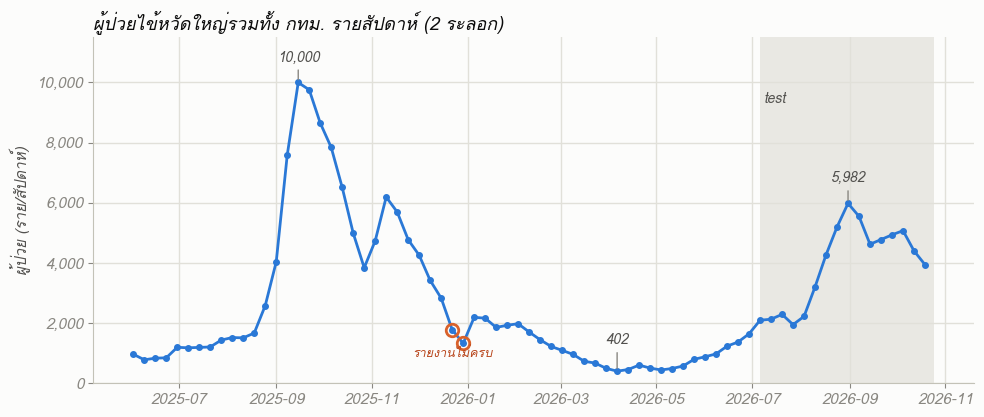

ระลอก 1 สูงสุด: สัปดาห์ 2025-09-15 = 10,000 ราย
ช่วงต่ำระหว่างฤดู: สัปดาห์ 2026-04-06 = 402 ราย
ระลอก 2 สูงสุด (ใน test): สัปดาห์ 2026-08-31 = 5,982 ราย
ระลอก 1 สูงกว่าระลอก 2: 1.67 เท่า | ระลอก 2 สูงกว่าช่วงต่ำ 14.9 เท่า
สัปดาห์สุดท้าย 2026-10-19: 3,942 ราย (สัปดาห์ก่อน 4,402)


In [20]:
fig, ax = plt.subplots(figsize=(10, 4.3))
ax.axvspan(TEST_START, tot.index[-1] + pd.Timedelta(days=6), color=GRID, alpha=0.7, lw=0)
ax.plot(tot.index, tot.values, color=BLUE, lw=2, marker='o', ms=4)
sus = tot[SUSPECT_WEEKS]
ax.plot(sus.index, sus.values, 'o', ms=9, mfc='none', mec='#d9622b', mew=2)
ax.text(sus.index[0], sus.values[0] - 900, T('รายงานไม่ครบ', 'under-reported'), color='#b8461c', fontsize=9, ha='center')

peak1 = tot[:'2025-12-15'].idxmax()                                        # ระลอก 1
low = tot['2026-01-05':TEST_START - pd.Timedelta(days=7)].idxmin()         # ช่วงต่ำระหว่างฤดู
peak2 = tot[TEST_START:].idxmax()                                          # ระลอก 2 (ใน test)
for w, dy in [(peak1, 700), (low, 900), (peak2, 700)]:
    ax.annotate(f'{tot[w]:,.0f}', (w, tot[w]), xytext=(w, tot[w] + dy), ha='center', fontsize=10,
                color=INK2, arrowprops=dict(arrowstyle='-', color=MUTED, lw=1))
ax.text(TEST_START + pd.Timedelta(days=2), tot.max() * 0.97, 'test', color=INK2, fontsize=10, va='top')
ax.set_title(T('ผู้ป่วยไข้หวัดใหญ่รวมทั้ง กทม. รายสัปดาห์ (2 ระลอก)', 'Weekly influenza cases, all Bangkok (two waves)'))
ax.set_ylabel(T('ผู้ป่วย (ราย/สัปดาห์)', 'cases per week'))
ax.set_ylim(0, tot.max() * 1.15)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:,.0f}'))
plt.tight_layout(); plt.show()

print(f'ระลอก 1 สูงสุด: สัปดาห์ {peak1.date()} = {tot[peak1]:,.0f} ราย')
print(f'ช่วงต่ำระหว่างฤดู: สัปดาห์ {low.date()} = {tot[low]:,.0f} ราย')
print(f'ระลอก 2 สูงสุด (ใน test): สัปดาห์ {peak2.date()} = {tot[peak2]:,.0f} ราย')
print(f'ระลอก 1 สูงกว่าระลอก 2: {tot[peak1] / tot[peak2]:.2f} เท่า | ระลอก 2 สูงกว่าช่วงต่ำ {tot[peak2] / tot[low]:.1f} เท่า')
print(f'สัปดาห์สุดท้าย {tot.index[-1].date()}: {tot.iloc[-1]:,.0f} ราย (สัปดาห์ก่อน {tot.iloc[-2]:,.0f})')


### กราฟที่ 2: ผู้ป่วยตามกลุ่มอายุ

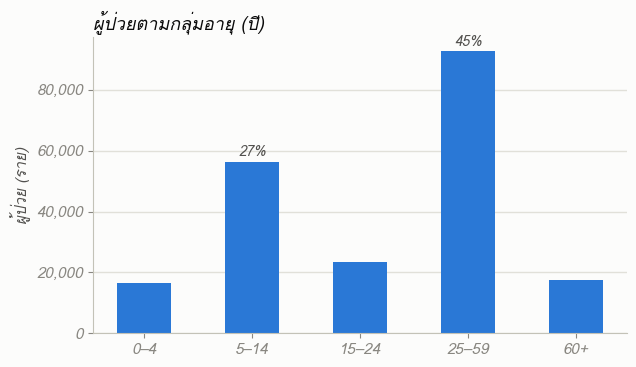

0-4       8.0
5-14     27.2
15-24    11.4
25-59    44.8
60+       8.5
ผู้ป่วยใน: 16.5% ของผู้ป่วยทั้งหมด
หมายเหตุ: ช่วงอายุกว้างไม่เท่ากัน (5, 10, 10, 35 ปี และ 60+) จึงเทียบความสูงแท่งตรงๆ เป็นอัตราป่วยไม่ได้


In [21]:
age_tot = tab[AGE_LABELS].sum()
age_share = 100 * age_tot / tab['cases'].sum()
fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.bar(['0–4', '5–14', '15–24', '25–59', '60+'], age_tot.values, color=BLUE, width=0.5)
for i in age_tot.sort_values().index[-2:]:
    k = AGE_LABELS.index(i)
    ax.text(k, age_tot[i] + age_tot.max() * 0.02, f'{age_share[i]:.0f}%', ha='center', color=INK2, fontsize=10)
ax.set_title(T('ผู้ป่วยตามกลุ่มอายุ (ปี)', 'Cases by age group (years)'))
ax.set_ylabel(T('ผู้ป่วย (ราย)', 'cases'))
ax.grid(axis='x', visible=False)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:,.0f}'))
plt.tight_layout(); plt.show()
print((age_share.round(1).rename(dict(zip(AGE_LABELS, ['0-4', '5-14', '15-24', '25-59', '60+'])))).to_string())
print('ผู้ป่วยใน: %.1f%% ของผู้ป่วยทั้งหมด' % (100 * tab['inpatient_cases'].sum() / tab['cases'].sum()))
print('หมายเหตุ: ช่วงอายุกว้างไม่เท่ากัน (5, 10, 10, 35 ปี และ 60+) จึงเทียบความสูงแท่งตรงๆ เป็นอัตราป่วยไม่ได้')

### กราฟที่ 3: 10 เขตที่มีผู้ป่วยสะสมสูงสุด


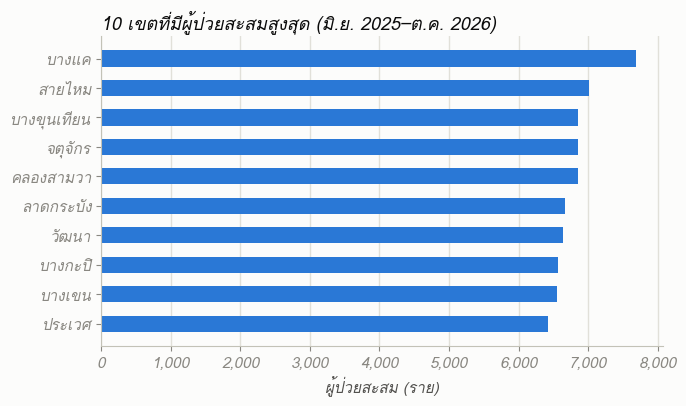

เขตสูงสุด: บางแค = 7686 ราย | เขตต่ำสุด: สัมพันธวงศ์ = 737 ราย
10 เขตสูงสุดรวมกัน = 33.0% ของผู้ป่วยทั้งหมด
หมายเหตุ: นี่เป็นจำนวนผู้ป่วย ไม่ใช่อัตราต่อประชากร (ไม่มีข้อมูลประชากรรายเขต)


In [22]:
dist_tot = tab.groupby('district')['cases'].sum().sort_values()
top10 = dist_tot.tail(10)
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.barh(top10.index, top10.values, color=BLUE, height=0.55)
ax.set_title(T('10 เขตที่มีผู้ป่วยสะสมสูงสุด (มิ.ย. 2025–ต.ค. 2026)', 'Top 10 districts by total cases (Jun 2025 - Oct 2026)'))
ax.set_xlabel(T('ผู้ป่วยสะสม (ราย)', 'total cases'))
ax.grid(axis='y', visible=False)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:,.0f}'))
plt.tight_layout(); plt.show()

print('เขตสูงสุด: %s = %d ราย | เขตต่ำสุด: %s = %d ราย' % (dist_tot.index[-1], dist_tot.iloc[-1], dist_tot.index[0], dist_tot.iloc[0]))
print('10 เขตสูงสุดรวมกัน = %.1f%% ของผู้ป่วยทั้งหมด' % (100 * top10.sum() / dist_tot.sum()))
print('หมายเหตุ: นี่เป็นจำนวนผู้ป่วย ไม่ใช่อัตราต่อประชากร (ไม่มีข้อมูลประชากรรายเขต)')

### กราฟที่ 4: เขตต่างๆ ขึ้นลงพร้อมกันหรือไม่ (เส้นสีเทา = แต่ละเขต หารด้วยค่าสูงสุดของเขตนั้น)

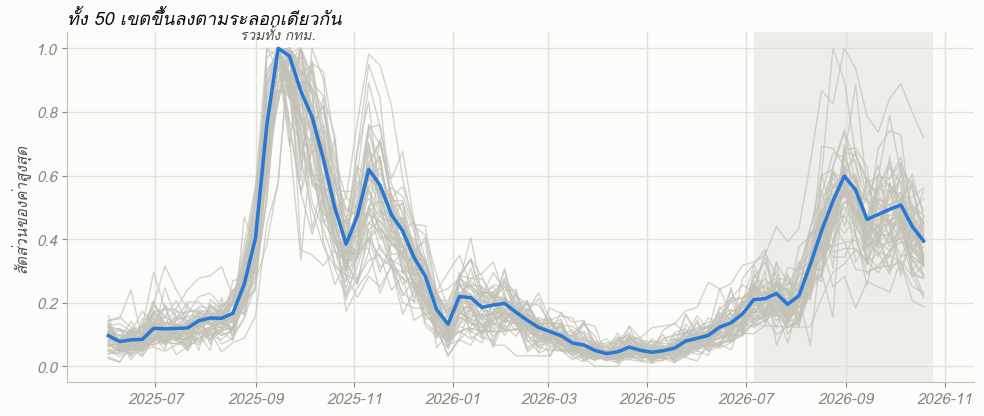

สหสัมพันธ์ของแต่ละเขตกับยอดรวม กทม.: มัธยฐาน 0.97 | ต่ำสุด 0.86 (สัมพันธวงศ์)
สหสัมพันธ์ระหว่างผู้ป่วยสัปดาห์ก่อนกับสัปดาห์นี้ (ทุกเขต-สัปดาห์): 0.93


In [23]:
norm = p_all.div(p_all.max(axis=1), axis=0)
fig, ax = plt.subplots(figsize=(10, 4.3))
for dname in norm.index:
    ax.plot(norm.columns, norm.loc[dname], color=GRAY, lw=1, alpha=0.7)
ax.plot(norm.columns, tot / tot.max(), color=BLUE, lw=2.5)
ax.axvspan(TEST_START, tot.index[-1] + pd.Timedelta(days=6), color=GRID, alpha=0.5, lw=0)
ax.set_title(T('ทั้ง 50 เขตขึ้นลงตามระลอกเดียวกัน', 'All 50 districts follow the same waves'))
ax.set_ylabel(T('สัดส่วนของค่าสูงสุด', 'share of own peak'))
ax.text(tot.idxmax(), 1.03, T('รวมทั้ง กทม.', 'all Bangkok'), color=INK2, fontsize=10, ha='center')
plt.tight_layout(); plt.show()

corr = p_all.apply(lambda r: np.corrcoef(r.values, tot.values)[0, 1], axis=1)
print('สหสัมพันธ์ของแต่ละเขตกับยอดรวม กทม.: มัธยฐาน %.2f | ต่ำสุด %.2f (%s)' % (corr.median(), corr.min(), corr.idxmin()))
lag_r = np.corrcoef(p_all.shift(1, axis=1).values[:, 1:].ravel(), p_all.values[:, 1:].ravel())[0, 1]
print('สหสัมพันธ์ระหว่างผู้ป่วยสัปดาห์ก่อนกับสัปดาห์นี้ (ทุกเขต-สัปดาห์): %.2f' % lag_r)

### ข้อสรุป R3

- รูปแบบตามเวลา: ในช่วง มิ.ย. 2025 – ต.ค. 2026 จำนวนผู้ป่วยไข้หวัดใหญ่ใน กทม. เปลี่ยนแปลงตามฤดูกาล ไม่ได้เพิ่มขึ้นอย่างต่อเนื่อง โดยฤดูฝนปี 2025 มียอดสูงสุด 10,000 ราย/สัปดาห์ (15 ก.ย. 2025) ก่อนลดลงเหลือ 402 ราย (6 เม.ย. 2026) และเพิ่มขึ้นอีกครั้งในฤดูฝนปี 2026 โดยสูงสุด 5,982 ราย/สัปดาห์ (31 ส.ค. 2026) ขณะที่ยอดสูงสุดของระลอกแรกสูงกว่า 1.67 เท่า ชุด Test (6 ก.ค. – 19 ต.ค. 2026) ครอบคลุมระลอกการระบาดครั้งที่สอง ส่วนชุด Train (ถึง 29 มิ.ย. 2026) ครอบคลุมระลอกแรก ช่วงผู้ป่วยต่ำ และช่วงเริ่มขึ้นของระลอกสอง (ถึง 1,645 ราย/สัปดาห์) แต่ยังไม่มียอดสูงสุดของระลอกสอง

- กลุ่มอายุและพื้นที่: ผู้ป่วยส่วนใหญ่อยู่ในช่วงอายุ 25–59 ปี (44.8%) และ 5–14 ปี (27.2%) ส่วนผู้ป่วยในคิดเป็น 16.5% ของผู้ป่วยทั้งหมด เขตบางแคมีผู้ป่วยสะสมสูงสุด 7,686 ราย ส่วนสัมพันธวงศ์ต่ำสุด 737 ราย ทั้งนี้ 10 เขตแรกมีผู้ป่วยรวม 33.0% ของทั้งหมด อย่างไรก็ตาม ตัวเลขดังกล่าวเป็นจำนวนผู้ป่วย ไม่ใช่อัตราต่อประชากร จึงไม่สามารถสรุปได้ว่ากลุ่มอายุหรือเขตใดมีความเสี่ยงสูงกว่าอย่างแท้จริง

- ความสัมพันธ์ระหว่างเขต: ทั้ง 50 เขตมีรูปแบบการเพิ่มขึ้นและลดลงของผู้ป่วยไปในทิศทางเดียวกัน โดยมีค่าสหสัมพันธ์กับยอดรวม กทม. มัธยฐาน 0.97 และต่ำสุด 0.86 ดังนั้น ข้อมูล Test จำนวน 800 แถว (50 เขต × 16 สัปดาห์) จึงมีความเป็นอิสระจริงใกล้เคียง 16 ช่วงเวลามากกว่า 800 จุด ส่งผลให้ผลการประเมินโมเดลอาจขึ้นอยู่กับบางช่วงของการระบาดเป็นหลัก

- ผลต่อการสร้างโมเดล: จำนวนผู้ป่วยสัปดาห์ก่อนและสัปดาห์ปัจจุบันมีค่าสหสัมพันธ์สูงถึง 0.93 ทำให้การใช้จำนวนผู้ป่วยสัปดาห์ก่อนเป็น Baseline มีประสิทธิภาพ และสนับสนุนการใช้ Lag Features อย่างไรก็ตาม โมเดลที่อาศัยข้อมูลย้อนหลังอาจคาดการณ์ไม่ทันในช่วงที่ผู้ป่วยเพิ่มขึ้นอย่างรวดเร็ว เช่น สิงหาคม 2026 ซึ่งต้องทดสอบเพิ่มเติมใน R5

- ข้อควรระวังของข้อมูล: ข้อมูลในสัปดาห์ที่ 22 และ 29 ธ.ค. 2025 (วงกลมสีส้มในกราฟ) มีแนวโน้มรายงานไม่ครบ จึงไม่นำมาใช้เป็นตัวแปรเป้าหมาย (Target) หรือข้อมูลย้อนหลัง (Lag) ของโมเดล ตามรายละเอียดในหัวข้อ 3.1

# R4 (ส่วนที่ 1) — Baseline: ค่าสัปดาห์ก่อนหน้าของเขตเดิม


In [24]:
tab = full.copy()    # ตารางเขต × สัปดาห์ที่สร้างจาก R2 ด้านบน

p = tab.pivot(index='district', columns='week_start', values='cases')   # แถว=เขต คอลัมน์=สัปดาห์
naive = p.shift(1, axis=1)          # ค่าที่ทำนาย = จำนวนผู้ป่วยของสัปดาห์ก่อนหน้า

weeks_all = list(p.columns)
t0 = weeks_all.index(TEST_START)                       # ตำแหน่งสัปดาห์แรกของ test
bad_idx = {weeks_all.index(w) for w in SUSPECT_WEEKS}  # สัปดาห์ที่รายงานไม่ครบ

def usable(k):
    """เป้าหมายสัปดาห์ k ใช้ได้เมื่อ k และ k-1..k-4 (ที่ baseline/feature ใช้) ไม่ใช่สัปดาห์ที่รายงานไม่ครบ"""
    return k >= 4 and not any((k - j) in bad_idx for j in range(0, 5))

train_idx = [k for k in range(4, t0) if usable(k)]
test_idx = list(range(t0, len(weeks_all)))
assert all(usable(k) for k in test_idx)
dropped = [weeks_all[k].date() for k in range(4, t0) if not usable(k)]
print('ตัดเป้าหมายออกจาก train (รายงานไม่ครบ/lag แตะสัปดาห์เหล่านั้น):', dropped[0], '→', dropped[-1], f'({len(dropped)} สัปดาห์)')
print('train:', weeks_all[train_idx[0]].date(), '→', weeks_all[train_idx[-1]].date(), '| สัปดาห์:', len(train_idx), '| แถว:', len(train_idx) * len(p))
print('test :', weeks_all[test_idx[0]].date(), '→', weeks_all[test_idx[-1]].date(), '| สัปดาห์:', len(test_idx), '| แถว:', len(test_idx) * len(p))
assert len(train_idx) * len(p) == 2350 and len(test_idx) * len(p) == 800

actual, pred = p.iloc[:, test_idx].values, naive.iloc[:, test_idx].values
BASE_MAE, BASE_UNDER = np.abs(actual - pred).mean(), 100 * (pred < actual).mean()
print('MAE = %.2f' % BASE_MAE)
print('ทำนายต่ำกว่าจริง = %.1f%%' % BASE_UNDER)

hits = []
for k in test_idx:
    top_actual = set(p.iloc[:, k].nlargest(10).index)      # 10 เขตสูงสุดจริง
    top_pred = set(naive.iloc[:, k].nlargest(10).index)    # 10 เขตที่ baseline ทำนายสูงสุด
    hits.append(len(top_actual & top_pred) / 10)
print('Top-10 hit rate = %.3f' % np.mean(hits))

# --- ทดสอบความไว: ไม่รวมสัปดาห์สุดท้ายของ test (ปลายข้อมูลอาจรายงานไม่ครบ) ---
a2, b2 = p.iloc[:, test_idx[:-1]].values, naive.iloc[:, test_idx[:-1]].values
print('\nไม่รวมสัปดาห์สุดท้ายของ test: MAE = %.2f | ต่ำกว่าจริง = %.1f%% | แถว: %d' % (np.abs(a2 - b2).mean(), 100 * (b2 < a2).mean(), a2.size))


ตัดเป้าหมายออกจาก train (รายงานไม่ครบ/lag แตะสัปดาห์เหล่านั้น): 2025-12-22 → 2026-01-26 (6 สัปดาห์)
train: 2025-06-30 → 2026-06-29 | สัปดาห์: 47 | แถว: 2350
test : 2026-07-06 → 2026-10-19 | สัปดาห์: 16 | แถว: 800
MAE = 16.06
ทำนายต่ำกว่าจริง = 54.9%
Top-10 hit rate = 0.738

ไม่รวมสัปดาห์สุดท้ายของ test: MAE = 16.25 | ต่ำกว่าจริง = 56.9% | แถว: 750


## R4 (ส่วนที่ 2) — โมเดลเทียบ baseline

**หลักการ (กัน data leakage และ test snooping):**
- ทุก feature ของสัปดาห์เป้าหมาย `k` ใช้เฉพาะข้อมูลสัปดาห์ `k-1` ย้อนหลัง (ข้อมูลที่รู้ ณ เช้าวันจันทร์) ห้ามใช้ข้อมูลของสัปดาห์ `k`
- เลือกพารามิเตอร์ด้วย **cross-validation ตามเวลาภายใน train เท่านั้น** (ฝึกช่วงก่อนหน้า ตรวจช่วงถัดไป ขยายหน้าต่างทีละช่วง) ไม่ดู test ระหว่างเลือก
- แถวที่เป้าหมายหรือ lag แตะสัปดาห์ 22 และ 29 ธ.ค. 2025 (รายงานไม่ครบ) ถูกตัดออกทั้งหมด
- test ใช้ครั้งเดียวหลังเลือกโมเดลเสร็จ และประเมินความไม่แน่นอนด้วย bootstrap ที่สุ่ม **สัปดาห์** (ไม่สุ่มแถว) เพราะทุกเขตขึ้นลงพร้อมกัน (ดู R3)

| Feature | ความหมาย |
|---|---|
| `lag1`–`lag4` | จำนวนผู้ป่วยของเขตนั้นย้อนหลัง 1–4 สัปดาห์ |
| `ma3` | ค่าเฉลี่ยของ 3 สัปดาห์ล่าสุด |
| `diff1` | `lag1 - lag2` (กำลังเพิ่มหรือลด) |
| `bkk_lag1`, `bkk_diff1` | ยอดรวม กทม. สัปดาห์ก่อน และการเปลี่ยนแปลงของยอดรวม |

In [25]:
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

P = p.values                       # แถว = เขต, คอลัมน์ = สัปดาห์ (73)
TOT = P.sum(axis=0)                # ยอดรวม กทม. รายสัปดาห์
rows = []
for k in range(4, P.shape[1]):     # k = สัปดาห์เป้าหมาย
    if not usable(k):
        continue                   # ข้ามสัปดาห์ที่ lag แตะข้อมูลที่รายงานไม่ครบ
    for i, dname in enumerate(p.index):
        lags = [P[i, k - j] for j in range(1, 5)]        # สัปดาห์ k-1 ... k-4 (รู้แล้ว ณ เช้าวันจันทร์)
        rows.append({'district': dname, 'week_idx': k, 'week': weeks_all[k], 'y': P[i, k],
                     'lag1': lags[0], 'lag2': lags[1], 'lag3': lags[2], 'lag4': lags[3],
                     'ma3': np.mean(lags[:3]), 'diff1': lags[0] - lags[1],
                     'bkk_lag1': TOT[k - 1], 'bkk_diff1': TOT[k - 1] - TOT[k - 2]})
data = pd.DataFrame(rows)
FEATURES = ['lag1', 'lag2', 'lag3', 'lag4', 'ma3', 'diff1', 'bkk_lag1', 'bkk_diff1']

# ตรวจ data leakage: feature ต้องมาจากสัปดาห์ก่อนหน้าเท่านั้น
district_pos = {d_: j for j, d_ in enumerate(p.index)}
for _, r in data.sample(300, random_state=0).iterrows():
    j, k = district_pos[r['district']], int(r['week_idx'])
    assert r['lag1'] == P[j, k - 1] and r['lag4'] == P[j, k - 4] and r['bkk_lag1'] == TOT[k - 1]
    assert r['y'] == P[j, k]

train = data[data['week_idx'] < t0].copy()
test = data[data['week_idx'] >= t0].copy()
print('train:', len(train), 'แถว | test:', len(test), 'แถว | features:', len(FEATURES))
assert len(train) == 2350 and len(test) == 800

train: 2350 แถว | test: 800 แถว | features: 8


### เลือกพารามิเตอร์ด้วย cross-validation ตามเวลา (ภายใน train เท่านั้น)

In [26]:
def make_ridge(a):
    return lambda: make_pipeline(StandardScaler(), Ridge(alpha=a))
def make_rf(depth, leaf):
    return lambda: RandomForestRegressor(n_estimators=100, max_depth=depth, min_samples_leaf=leaf,
                                         random_state=0, n_jobs=-1)

CANDIDATES = {
    'Ridge': {f'alpha={a}': make_ridge(a) for a in [1, 10, 100, 1000]},
    'RandomForest': {f'depth={dp}, leaf={lf}': make_rf(dp, lf) for dp, lf in [(3, 20), (5, 10)]},
}
# ตรวจบนช่วงถัดไปภายใน train 3 ช่วง (ขยายหน้าต่างฝึกทีละช่วง ไม่ย้อนอนาคต)
FOLD_VAL = [range(35, 43), range(43, 50), range(50, 57)]   # 2 ก.พ.–23 มี.ค. | 30 มี.ค.–11 พ.ค. | 18 พ.ค.–29 มิ.ย. 2026
assert all(k in train_idx for va in FOLD_VAL for k in va)
for va in FOLD_VAL:
    print('ตรวจ:', weeks_all[va[0]].date(), '→', weeks_all[va[-1]].date(),
          '| ฝึกด้วยสัปดาห์เป้าหมายก่อนหน้า', sum(k < va[0] for k in train_idx), 'สัปดาห์')

def cv_eval(factory=None):
    maes, unders = [], []
    for va_w in FOLD_VAL:
        tr_w = [k for k in train_idx if k < va_w[0]]
        a = train[train['week_idx'].isin(tr_w)]
        b = train[train['week_idx'].isin(va_w)]
        pr = b['lag1'].values.astype(float) if factory is None else factory().fit(a[FEATURES], a['y']).predict(b[FEATURES])
        maes.append(np.abs(pr - b['y'].values).mean()); unders.append((pr < b['y'].values).mean())
    return np.mean(maes), 100 * np.mean(unders)

cv_rows = [('baseline (ค่าสัปดาห์ก่อน)', '-') + cv_eval(None)]
best = {}
for fam, cands in CANDIDATES.items():
    scores = {name: cv_eval(f) for name, f in cands.items()}
    for name, (m_, u_) in scores.items():
        cv_rows.append((fam, name, m_, u_))
    best[fam] = min(scores, key=lambda n: scores[n][0])
cv_table = pd.DataFrame(cv_rows, columns=['โมเดล', 'พารามิเตอร์', 'CV MAE', 'ต่ำกว่าจริง %'])
print(cv_table.round(2).to_string(index=False))
print('\nพารามิเตอร์ที่เลือก (MAE ต่ำสุดใน CV):', best)

ตรวจ: 2026-02-02 → 2026-03-23 | ฝึกด้วยสัปดาห์เป้าหมายก่อนหน้า 25 สัปดาห์
ตรวจ: 2026-03-30 → 2026-05-11 | ฝึกด้วยสัปดาห์เป้าหมายก่อนหน้า 33 สัปดาห์
ตรวจ: 2026-05-18 → 2026-06-29 | ฝึกด้วยสัปดาห์เป้าหมายก่อนหน้า 40 สัปดาห์
                    โมเดล      พารามิเตอร์  CV MAE  ต่ำกว่าจริง %
baseline (ค่าสัปดาห์ก่อน)                -    5.62          47.05
                    Ridge          alpha=1    7.44          19.31
                    Ridge         alpha=10    7.43          19.60
                    Ridge        alpha=100    7.41          19.98
                    Ridge       alpha=1000   10.86          10.98
             RandomForest depth=3, leaf=20    8.82          26.37
             RandomForest depth=5, leaf=10    6.42          32.88

พารามิเตอร์ที่เลือก (MAE ต่ำสุดใน CV): {'Ridge': 'alpha=100', 'RandomForest': 'depth=5, leaf=10'}


### ฝึกบน train ทั้งหมด แล้วประเมินบน test ครั้งเดียว

In [27]:
final = {fam: CANDIDATES[fam][best[fam]]().fit(train[FEATURES], train['y']) for fam in CANDIDATES}
preds = {'baseline': test['lag1'].values.astype(float)}
for fam, m_ in final.items():
    preds[fam] = m_.predict(test[FEATURES])

y_te = test['y'].values
last_w = test['week_idx'].max()
mask_ex = (test['week_idx'] < last_w).values          # ไม่รวมสัปดาห์สุดท้ายของ test (19 ต.ค.)

def top10_hit(pred):
    hits = []
    for w, g in test.assign(pred=pred).groupby('week_idx'):
        hits.append(len(set(g.nlargest(10, 'y')['district']) & set(g.nlargest(10, 'pred')['district'])) / 10)
    return np.mean(hits)

res_rows = []
for name, pr in preds.items():
    res_rows.append({'โมเดล': name,
                     'MAE': np.abs(pr - y_te).mean(),
                     'ต่ำกว่าจริง %': 100 * (pr < y_te).mean(),
                     'Top-10 hit': top10_hit(pr),
                     'MAE (ไม่รวมสัปดาห์สุดท้าย)': np.abs(pr - y_te)[mask_ex].mean(),
                     'ต่ำกว่าจริง % (ไม่รวมสัปดาห์สุดท้าย)': 100 * (pr < y_te)[mask_ex].mean()})
res_table = pd.DataFrame(res_rows).set_index('โมเดล')
print(res_table.round(2).to_string())
assert abs(res_table.loc['baseline', 'MAE'] - BASE_MAE) < 1e-9, 'baseline ไม่ตรงกับส่วนที่ 1'

                MAE  ต่ำกว่าจริง %  Top-10 hit  MAE (ไม่รวมสัปดาห์สุดท้าย)  ต่ำกว่าจริง % (ไม่รวมสัปดาห์สุดท้าย)
โมเดล                                                                                                           
baseline      16.06          54.87        0.74                       16.25                                 56.93
Ridge         14.90          53.75        0.76                       15.08                                 52.67
RandomForest  17.07          55.38        0.71                       17.35                                 55.33


### ความไม่แน่นอน: bootstrap สุ่ม **สัปดาห์** (เพราะทุกเขตขึ้นลงพร้อมกัน จึงสุ่มแถวไม่ได้)

In [28]:
rng = np.random.default_rng(42)
wk_list = sorted(test['week_idx'].unique())
wk_mae = {n: np.array([np.abs(pr - y_te)[(test['week_idx'] == w).values].mean() for w in wk_list])
          for n, pr in preds.items()}
boot = rng.integers(0, len(wk_list), size=(5000, len(wk_list)))      # สุ่มสัปดาห์ 8 ครั้ง คืนที่ 5,000 รอบ

print('MAE เฉลี่ยรายสัปดาห์ และช่วงความเชื่อมั่น 95% (bootstrap สัปดาห์):')
ci = {}
for n in preds:
    b_ = wk_mae[n][boot].mean(axis=1)
    ci[n] = np.percentile(b_, [2.5, 97.5])
    print(f'  {n:13s} {wk_mae[n].mean():6.2f}  [{ci[n][0]:.2f}, {ci[n][1]:.2f}]')
print('\nผลต่างเทียบ baseline (ลบ = โมเดลดีกว่า):')
for n in preds:
    if n == 'baseline':
        continue
    dlt = (wk_mae[n] - wk_mae['baseline'])[boot].mean(axis=1)
    lo, hi = np.percentile(dlt, [2.5, 97.5])
    print(f'  {n:13s} {np.mean(wk_mae[n] - wk_mae["baseline"]):+6.2f}  [{lo:+.2f}, {hi:+.2f}]  | โมเดลดีกว่าใน {100 * (dlt < 0).mean():.0f}% ของรอบ bootstrap')
print('\nจำนวนสัปดาห์ test ที่โมเดลมี MAE ต่ำกว่า baseline:')
for n in preds:
    if n != 'baseline':
        print(f'  {n:13s} {int((wk_mae[n] < wk_mae["baseline"]).sum())} จาก {len(wk_list)} สัปดาห์')

MAE เฉลี่ยรายสัปดาห์ และช่วงความเชื่อมั่น 95% (bootstrap สัปดาห์):
  baseline       16.06  [13.75, 18.44]
  Ridge          14.90  [12.91, 17.04]
  RandomForest   17.07  [14.34, 20.10]

ผลต่างเทียบ baseline (ลบ = โมเดลดีกว่า):
  Ridge          -1.16  [-3.28, +0.77]  | โมเดลดีกว่าใน 88% ของรอบ bootstrap
  RandomForest   +1.01  [-0.77, +2.64]  | โมเดลดีกว่าใน 13% ของรอบ bootstrap

จำนวนสัปดาห์ test ที่โมเดลมี MAE ต่ำกว่า baseline:
  Ridge         10 จาก 16 สัปดาห์
  RandomForest  6 จาก 16 สัปดาห์


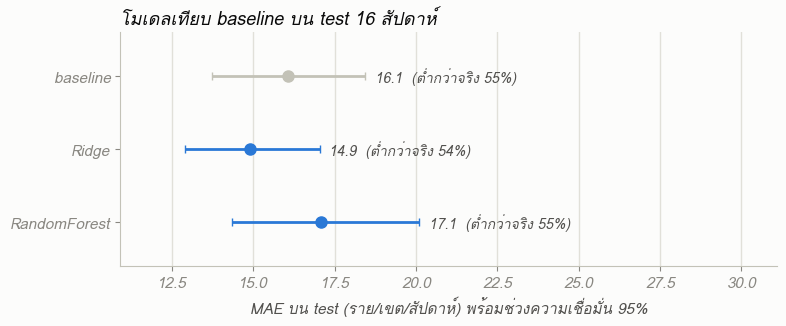

,district,week,week_idx,y,baseline,Ridge,RandomForest
2350,คลองสาน,2026-07-06,57,28,22.0,28.486993,26.603843
2351,คลองสามวา,2026-07-06,57,74,81.0,78.250462,57.688031
2352,คลองเตย,2026-07-06,57,35,27.0,35.163674,27.845401
2353,คันนายาว,2026-07-06,57,45,31.0,33.253874,35.108104
2354,จตุจักร,2026-07-06,57,69,60.0,60.571982,55.891820


In [29]:
fig, ax = plt.subplots(figsize=(8, 3.4))
names = list(preds)
for y_, n in enumerate(reversed(names)):
    m_ = wk_mae[n].mean(); lo, hi = ci[n]
    ax.errorbar(m_, y_, xerr=[[m_ - lo], [hi - m_]], fmt='o', ms=8, lw=2, capsize=3,
                color=GRAY if n == 'baseline' else BLUE)
    ax.text(hi + 0.3, y_, f"{m_:.1f}  (ต่ำกว่าจริง {res_table.loc[n, 'ต่ำกว่าจริง %']:.0f}%)" if TH
            else f"{m_:.1f}  (under {res_table.loc[n, 'ต่ำกว่าจริง %']:.0f}%)",
            va='center', color=INK2, fontsize=10)
ax.set_yticks(range(len(names))); ax.set_yticklabels(list(reversed(names)))
ax.set_ylim(-0.6, len(names) - 0.4)
ax.set_xlim(min(c[0] for c in ci.values()) - 2, max(c[1] for c in ci.values()) + 11)
ax.set_xlabel(T('MAE บน test (ราย/เขต/สัปดาห์) พร้อมช่วงความเชื่อมั่น 95%', 'test MAE (cases/district/week), 95% CI'))
ax.set_title(T(f'โมเดลเทียบ baseline บน test {len(wk_list)} สัปดาห์', f'Models vs baseline on the {len(wk_list)}-week test set'))
ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()

# เก็บผลทำนายไว้ใช้ใน R5 (วิเคราะห์จุดที่พลาด)
results = test[['district', 'week', 'week_idx', 'y']].copy()
for n, pr in preds.items():
    results[n] = pr
results.head()

### ข้อสรุป R4

1. โมเดลชนะ Baseline หรือไม่: ผลยังไม่ชัดเจน โดย Ridge มี MAE 14.90 ดีกว่า Baseline ที่ 16.06 และชนะใน 10 จาก 16 สัปดาห์ รวมถึงมี Top-10 Hit Rate สูงกว่าเล็กน้อย (0.76 เทียบกับ 0.74) แต่ยังทำนายต่ำกว่าค่าจริงใกล้เคียงกัน (53.8% เทียบกับ 54.9%) ส่วน Random Forest ให้ผลแย่กว่า Baseline ทั้ง 3 ตัวชี้วัด

2. ช่วงความเชื่อมั่น 95%: ผลต่าง MAE ของ Ridge อยู่ที่ −1.16 [−3.28, +0.77] และ Random Forest อยู่ที่ +1.01 [−0.77, +2.64] ซึ่งทั้งสองช่วงคร่อม 0 จึงยังยืนยันไม่ได้ว่าโมเดลใดดีกว่า Baseline แม้ Ridge จะมีโอกาสให้ผลดีกว่าใน Bootstrap 88% ก็ตาม เนื่องจาก Test มีเพียง 16 สัปดาห์ และข้อมูลแต่ละเขตมีความสัมพันธ์กัน นอกจากนี้ ผล Cross-validation ใน Train (ก.พ.–มิ.ย. 2026 ซึ่งเป็นช่วงผู้ป่วยน้อยถึงเริ่มเพิ่ม) พบว่า Baseline ดีกว่าทั้งสองโมเดล (MAE 5.62 เทียบกับ 7.41 ของ Ridge และ 6.42 ของ Random Forest) ซึ่งตรงข้ามกับผลบน Test จึงอาจสะท้อนว่าอันดับของโมเดลไม่คงที่ข้ามช่วงเวลา แต่ด้วยข้อมูลเพียงสองช่วง ยังแยกไม่ได้ว่าเกิดจากฤดูกาลหรือความบังเอิญ

3. ความเหมาะสมกับสำนักอนามัย: เมื่อการทำนายต่ำกว่าค่าจริงมีความเสี่ยงสูง ทั้งสามวิธียังมีข้อจำกัด เพราะทำนายต่ำกว่าจริงประมาณ 54–55% ของข้อมูล Ridge ดีกว่าเล็กน้อยแต่ยังไม่มีหลักฐานยืนยันชัดเจน ดังนั้น Baseline จึงเหมาะเป็นเครื่องมือประกอบการตัดสินใจมากกว่า เนื่องจากเรียบง่าย อธิบายและตรวจสอบได้ง่าย ส่วน Ridge ควรใช้เป็นเครื่องมือเสริมและทดสอบเพิ่มเติมในฤดูถัดไป


# R5 — โมเดลพลาดตรงไหน

**คำถามที่ต้องตอบได้:** ความผิดพลาดกระจุกอยู่ที่ไหน (สัปดาห์ไหน / เขตไหน / ช่วงไหนของระลอก) และเมื่อพลาดแล้วกระทบการตัดสินใจของสำนักอนามัยอย่างไร

**หมายเหตุวิธีวิเคราะห์:** การแยก "ช่วงขาขึ้น/ขาลง" ใช้ยอดรวม กทม. จริงของสัปดาห์เป้าหมายเทียบสัปดาห์ก่อน ซึ่ง**ไม่ได้รู้ล่วงหน้า**ตอนทำนาย ใช้เพื่อวิเคราะห์ย้อนหลังเท่านั้น ไม่ใช่ feature ของโมเดล


### 5.1 ยอดรวม กทม.: ค่าจริง vs ค่าทำนาย

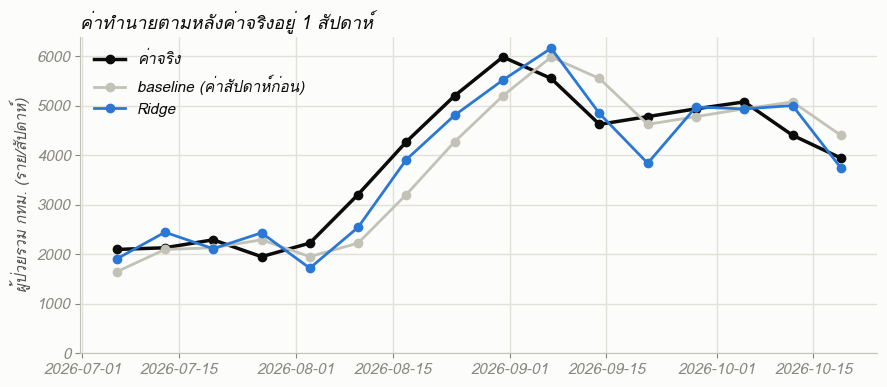

               y  baseline  Ridge  RandomForest
week                                           
2026-07-06  2096      1645   1906          1692
2026-07-13  2130      2096   2444          2121
2026-07-20  2291      2130   2111          2077
2026-07-27  1950      2291   2432          2222
2026-08-03  2224      1950   1719          1814
2026-08-10  3205      2224   2543          2136
2026-08-17  4270      3205   3910          5132
2026-08-24  5198      4270   4805          6106
2026-08-31  5982      5198   5516          5936
2026-09-07  5548      5982   6158          6145
2026-09-14  4622      5548   4841          4900
2026-09-21  4778      4622   3837          4103
2026-09-28  4935      4778   4972          4422
2026-10-05  5075      4935   4933          4592
2026-10-12  4402      5075   5001          4657
2026-10-19  3942      4402   3746          4055


In [30]:

MODELS = [c for c in results.columns if c not in ('district', 'week', 'week_idx', 'y')]   # baseline, Ridge, RandomForest
wk = results.groupby('week')[['y'] + MODELS].sum()
wk.index = pd.to_datetime(wk.index)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(wk.index, wk['y'], color=INK, lw=2.5, marker='o', label=T('ค่าจริง', 'actual'))
ax.plot(wk.index, wk['baseline'], color=GRAY, lw=2, marker='o', label=T('baseline (ค่าสัปดาห์ก่อน)', 'baseline (last week)'))
ax.plot(wk.index, wk['Ridge'], color=BLUE, lw=2, marker='o', label='Ridge')
ax.set_ylim(bottom=0)
ax.set_ylabel(T('ผู้ป่วยรวม กทม. (ราย/สัปดาห์)', 'BKK total cases / week'))
ax.set_title(T('ค่าทำนายตามหลังค่าจริงอยู่ 1 สัปดาห์', 'Predictions lag the actual by one week'))
ax.legend(frameon=False)
plt.tight_layout(); plt.show()
print((wk.round(0)).astype(int).to_string())


### 5.2 ผิดพลาดแยกตามช่วงของระลอก: ขาขึ้น vs ขาลง

In [31]:

tot_actual = pd.Series(TOT, index=pd.to_datetime(weeks_all))
chg = tot_actual.diff()
phase = chg.map(lambda v: 'ขาขึ้น' if v > 0 else 'ขาลง')
results['phase'] = pd.to_datetime(results['week']).map(phase)

rows = []
for ph, g in results.groupby('phase'):
    for m_ in MODELS:
        e = g[m_] - g['y']
        rows.append({'ช่วง': ph, 'โมเดล': m_, 'สัปดาห์': g['week'].nunique(),
                     'MAE': e.abs().mean(), 'ต่ำกว่าจริง %': 100 * (e < 0).mean(),
                     'พลาดต่ำเฉลี่ย (ราย/เขต)': e[e < 0].mean() if (e < 0).any() else 0.0})
ph_tab = pd.DataFrame(rows)
print(ph_tab.round(1).to_string(index=False))

print('\nรายสัปดาห์ (baseline): ผลต่างยอดรวม กทม. สัปดาห์นั้นเทียบสัปดาห์ก่อน, ทำนายต่ำ %, ผู้ป่วยที่ "ขาด" รวม กทม.')
b = results.copy(); b['err'] = b['baseline'] - b['y']
w_ = b.groupby('week').agg(ต่ำกว่าจริง_pct=('err', lambda s: 100 * (s < 0).mean()),
                           ขาดรวม=('err', lambda s: -s[s < 0].sum()), เกินรวม=('err', lambda s: s[s > 0].sum()))
w_['เปลี่ยนจากสัปดาห์ก่อน'] = chg.reindex(pd.to_datetime(w_.index)).values
print(w_.round(0).astype(int).to_string())


  ช่วง        โมเดล  สัปดาห์  MAE  ต่ำกว่าจริง %  พลาดต่ำเฉลี่ย (ราย/เขต)
ขาขึ้น     baseline       11 15.7           68.9                    -18.1
ขาขึ้น        Ridge       11 14.7           63.3                    -16.6
ขาขึ้น RandomForest       11 18.1           63.8                    -17.1
  ขาลง     baseline        5 16.9           24.0                    -11.6
  ขาลง        Ridge        5 15.4           32.8                    -13.0
  ขาลง RandomForest        5 14.8           36.8                    -11.8

รายสัปดาห์ (baseline): ผลต่างยอดรวม กทม. สัปดาห์นั้นเทียบสัปดาห์ก่อน, ทำนายต่ำ %, ผู้ป่วยที่ "ขาด" รวม กทม.
            ต่ํากว่าจริง_pct  ขาดรวม  เกินรวม  เปลี่ยนจากสัปดาห์ก่อน
week                                                                
2026-07-06                80     504       53                    451
2026-07-13                52     219      185                     34
2026-07-20                58     378      217                    161
2026-07-27                30

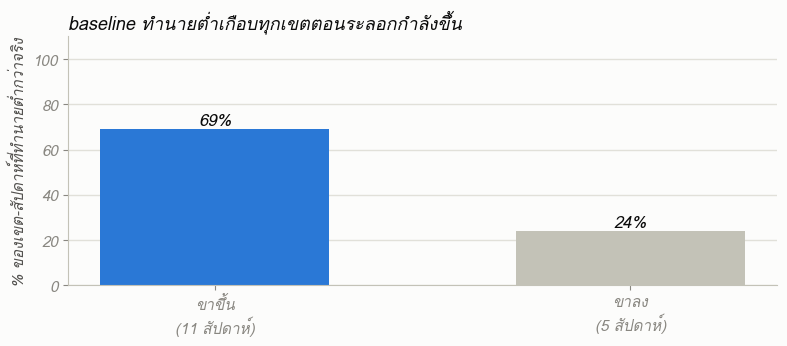

In [32]:

fig, ax = plt.subplots(figsize=(8, 3.6))
ph_b = ph_tab[ph_tab['โมเดล'] == 'baseline'].set_index('ช่วง')
xs = np.arange(len(ph_b))
ax.bar(xs, ph_b['ต่ำกว่าจริง %'], color=[BLUE if i == 'ขาขึ้น' else GRAY for i in ph_b.index], width=0.55)
for x_, v_ in zip(xs, ph_b['ต่ำกว่าจริง %']):
    ax.text(x_, v_ + 2, f'{v_:.0f}%', ha='center', color=INK, fontsize=12)
ax.set_xticks(xs)
ax.set_xticklabels([f"{i}\n({int(ph_b.loc[i, 'สัปดาห์'])} สัปดาห์)" for i in ph_b.index])
ax.set_ylim(0, 110); ax.set_ylabel(T('% ของเขต-สัปดาห์ที่ทำนายต่ำกว่าจริง', '% of district-weeks under-predicted'))
ax.set_title(T('baseline ทำนายต่ำเกือบทุกเขตตอนระลอกกำลังขึ้น', 'Baseline under-predicts almost everywhere when the wave is rising'))
ax.grid(axis='x', visible=False)
plt.tight_layout(); plt.show()


### 5.3 เขตและสัปดาห์ที่ error สูงสุด

In [33]:

b['abs_err'] = b['err'].abs()
print('10 เขต-สัปดาห์ที่ baseline พลาดมากที่สุด:')
print(b.nlargest(10, 'abs_err')[['district', 'week', 'y', 'baseline', 'err']]
      .rename(columns={'y': 'จริง', 'baseline': 'ทำนาย', 'err': 'ทำนาย-จริง'}).to_string(index=False))

d = b.groupby('district').agg(MAE=('abs_err', 'mean'), ค่าจริงเฉลี่ย=('y', 'mean'))
d['MAE เทียบค่าจริง %'] = 100 * d['MAE'] / d['ค่าจริงเฉลี่ย']
print('\n5 เขตที่ MAE สูงสุด:'); print(d.nlargest(5, 'MAE').round(1).to_string())
print('\nสหสัมพันธ์ ขนาดเขต (ค่าจริงเฉลี่ย) กับ MAE:', round(d['ค่าจริงเฉลี่ย'].corr(d['MAE']), 2))
print('MAE เทียบค่าจริง %: มัธยฐาน', round(d['MAE เทียบค่าจริง %'].median(), 1), '| ต่ำสุด', round(d['MAE เทียบค่าจริง %'].min(), 1), '| สูงสุด', round(d['MAE เทียบค่าจริง %'].max(), 1))
share = b.groupby('district')['abs_err'].sum().sort_values(ascending=False)
print('10 เขตแรก คิดเป็น', round(100 * share.head(10).sum() / share.sum(), 1), '% ของ error รวม (ถ้ากระจายเท่ากัน = 20%)')


10 เขต-สัปดาห์ที่ baseline พลาดมากที่สุด:
  district       week  จริง  ทำนาย  ทำนาย-จริง
     วัฒนา 2026-08-31   224   53.0      -171.0
     วัฒนา 2026-09-14   190  302.0       112.0
     บางแค 2026-08-10   133   49.0       -84.0
   บางกะปิ 2026-08-24   187  104.0       -83.0
   มีนบุรี 2026-08-31   180   97.0       -83.0
วังทองหลาง 2026-08-24   138   60.0       -78.0
     วัฒนา 2026-09-07   302  224.0       -78.0
 ลาดกระบัง 2026-09-21   110  182.0        72.0
 ภาษีเจริญ 2026-10-19    91  160.0        69.0
     บางแค 2026-10-19   156  220.0        64.0

5 เขตที่ MAE สูงสุด:
            MAE  ค่าจริงเฉลี่ย  MAE เทียบค่าจริง %
district                                          
วัฒนา      35.7          131.8                27.1
บางแค      28.5          153.4                18.6
ลาดกระบัง  26.9          123.8                21.7
สายไหม     26.9          128.4                20.9
คลองสามวา  25.6          136.1                18.8

สหสัมพันธ์ ขนาดเขต (ค่าจริงเฉลี่ย) กับ MAE: 0.87
MAE เทียบค่า

### 5.4 Top-10 hit rate รายสัปดาห์ (เลือกเขตที่ควรส่งทีมถูกกี่เขต)

In [34]:

hit_rows = []
for w, g in results.groupby('week'):
    true10 = set(g.nlargest(10, 'y')['district'])
    hit_rows.append({'week': w, **{m_: len(true10 & set(g.nlargest(10, m_)['district'])) for m_ in MODELS}})
hit = pd.DataFrame(hit_rows).set_index('week')
print('จำนวนเขตที่ถูก จากทั้งหมด 10 ในแต่ละสัปดาห์:'); print(hit.to_string())
print('\nเฉลี่ย:', (hit.mean() / 10).round(3).to_dict())


จำนวนเขตที่ถูก จากทั้งหมด 10 ในแต่ละสัปดาห์:
            baseline  Ridge  RandomForest
week                                     
2026-07-06         7      8             8
2026-07-13         8      8             7
2026-07-20         7      8             7
2026-07-27         6      6             7
2026-08-03         7      8             8
2026-08-10         7      8             8
2026-08-17         8      8             8
2026-08-24         8      8             5
2026-08-31         7      7             6
2026-09-07         9      9             8
2026-09-14         8      8             8
2026-09-21         8      8             8
2026-09-28         7      7             6
2026-10-05         6      6             6
2026-10-12         7      7             7
2026-10-19         8      7             7

เฉลี่ย: {'baseline': 0.738, 'Ridge': 0.756, 'RandomForest': 0.712}


### ข้อสรุป R5

1. ความผิดพลาดกระจุกอยู่ที่ไหน: ความผิดพลาดส่วนใหญ่อยู่ในช่วงผู้ป่วยเพิ่มขึ้น โดย Baseline ทำนายต่ำกว่าจริง 69% ของเขต-สัปดาห์ เทียบกับ 24% ในช่วงผู้ป่วยลดลง โดยช่วงที่พลาดหนักที่สุดคือ 10–24 ส.ค. 2026 (ทำนายต่ำ 74–94% ของเขต และผู้ป่วยที่ขาดรวมทั้ง กทม. กว่า 1,000 ราย/สัปดาห์) เช่น วันที่ 17 ส.ค. มียอดผู้ป่วยจริง 4,270 ราย แต่ทำนายเพียง 3,205 ราย นอกจากนี้ เขตขนาดใหญ่มีแนวโน้มคลาดเคลื่อนสูงกว่า (สหสัมพันธ์ 0.87) โดยเขตวัฒนามี MAE สูงสุด 35.7 อย่างไรก็ตาม เมื่อเทียบกับจำนวนผู้ป่วยจริง ความคลาดเคลื่อนอยู่ที่ 11–45% (มัธยฐาน 21%) และ 10 เขตแรกคิดเป็น 32.5% ของความผิดพลาดทั้งหมด

2. ข้อจำกัดของตัวเลขภาพรวม: ตัวเลขการทำนายต่ำกว่าจริง 54.9% อาจปิดบังปัญหาในช่วงขาขึ้น เนื่องจากช่วงขาลงมีการทำนายต่ำเพียง 24% ขณะที่ช่วงขาขึ้นสูงถึง 69% และเพิ่มเป็น 90% ขึ้นไปในช่วงที่ผู้ป่วยพุ่งสูงอย่างรวดเร็ว ทั้ง Ridge และ Random Forest ก็มีปัญหาเดียวกัน โดยทำนายต่ำในช่วงขาขึ้น 63% และ 64% ตามลำดับ

3. ผลกระทบต่อการตัดสินใจ: หากใช้ Baseline วางแผนจัดสรรบุคลากรและยาในช่วงที่ผู้ป่วยเริ่มเพิ่มขึ้น อาจทำให้ทรัพยากรไม่เพียงพอในหลายเขตพร้อมกัน (ราว 7 ใน 10 เขตของสัปดาห์ขาขึ้น และเกิน 9 ใน 10 เขตในสัปดาห์ 10 และ 17 ส.ค.) เนื่องจากค่าทำนายตามหลังข้อมูลจริง 1 สัปดาห์ และอาจประเมินจำนวนผู้ป่วยต่ำกว่าจริงประมาณ 1,000 ราย/สัปดาห์ในช่วงที่ระบาดรวดเร็ว อย่างไรก็ตาม ขณะทำนายยังไม่ทราบล่วงหน้าว่าสัปดาห์นั้นเป็นช่วงขาขึ้น เพราะการจำแนกใช้ยอดผู้ป่วยจริงของสัปดาห์เป้าหมาย ซึ่งเป็นข้อมูลที่ยังไม่ทราบในเวลาทำนาย

4. ข้อจำกัดของการวิเคราะห์: ชุด Test มีเพียง 16 สัปดาห์ จากฤดูการระบาดเดียว โดยช่วงที่ผู้ป่วยรวมเพิ่มกว่า 900 ราย/สัปดาห์มีเพียง 3 สัปดาห์ (10, 17 และ 24 ส.ค.) อีกทั้งการจำแนกช่วงขาขึ้นนับทุกสัปดาห์ที่ยอดผู้ป่วยเพิ่มขึ้น แม้เพิ่มเพียงเล็กน้อย จึงอาจไม่สะท้อนช่วงการระบาดรุนแรงทั้งหมด ผลการวิเคราะห์จึงแสดงเพียงความสัมพันธ์ ไม่ใช่ข้อสรุปด้านเหตุและผล

# R7 — บันทึกการใช้ AI

กติกา: AI เป็นผู้ช่วย ไม่ใช่ผู้ทำ ต้องมีอย่างน้อย 1 ข้อที่กลุ่ม **ไม่ทำตามหรือแก้คำแนะนำของ AI พร้อมเหตุผล** (ตารางนี้ร่างจากการทำงานจริง ช่อง `[...]` กลุ่มต้องยืนยันหรือเติมเอง)

| # | ใช้ AI ทำอะไร | AI เสนอ/ทำ | กลุ่มทำอย่างไร | เหตุผล |
|---|---|---|---|---|
| 1 | ตั้งโจทย์และจำนวนแถว | เสนอทางเลือกการนับแถว (รายเขต-สัปดาห์ ฯลฯ) และช่วยเกลาประโยคโจทย์/คำตอบ R1 | กลุ่มเลือกหน่วยข้อมูล 1 เขต × 1 สัปดาห์ เขียนโจทย์และคำตอบ R1 เอง AI เกลาถ้อยคำ | ต้องการ ≥ ~1,000 แถวโดยเป้าหมายไม่ซ้อนทับกัน |
| 2 | จำนวนเขต | AI คาดว่ามี **51 เขต** | **ไม่ทำตาม/แก้:** ตรวจข้อมูลจริง พบ “เขตบางพลัด” สะกดต่าง (มีคำนำหน้า “เขต”) → รวมเป็น **50 เขต** | AI คาดผิด กลุ่มตรวจกับข้อมูลจริง |
| 3 | นับแถวซ้ำ | AI นับแถวซ้ำผิดครั้งแรก (648) | แก้เป็นตัวเลขที่ตรวจได้ใน notebook (ไข้หวัดใหญ่ 423 แถวส่วนเกิน) | ตรวจซ้ำด้วยโค้ด ไม่เชื่อตัวเลขจาก AI |
| 4 | จัดการแถวซ้ำ | AI ให้ทางเลือกลบ/เก็บ | กลุ่มตัดสินใจ **เก็บไว้** และทดสอบความไว (baseline MAE 16.06 เทียบ 15.99 เมื่อลบ) | ไม่มีรหัสผู้ป่วย พิสูจน์ไม่ได้ว่าเป็นคนเดียวกัน `[ยืนยัน]` |
| 5 | ข้อมูลเพิ่มปี 2026 | AI แนะนำ **ทางเลือก B** (ฝึกด้วยข้อมูลเดิม ทดสอบด้วยข้อมูล 2026) และบอกว่า A เสี่ยงต่ำสุด | กลุ่มเลือก A ก่อน แล้วเปลี่ยนเป็น **C** (รวมทั้งหมด ออกแบบ train/test ใหม่) | `[กลุ่มเติมเหตุผล เช่น ต้องการข้อมูลครบทั้งช่วงและ test เป็นฤดูที่สอง ทั้งที่มีความเสี่ยงเรื่องเวลา]` |
| 6 | ตรวจคุณภาพข้อมูลใหม่ | AI พบแถวว่าง 692,832 แถวในไฟล์ ม.ค.–มิ.ย. 2026 และรายงานล่าช้าปลายไฟล์ 2025 | ลบแถวว่าง และตัดสัปดาห์ 22 ธ.ค. กับ 29 ธ.ค. 2025 (รวมเป้าหมายที่ lag แตะ 6 สัปดาห์) ออกจากการฝึก/ทดสอบ | ปลายไฟล์ 2025 ผู้ป่วยรายวันลดฮวบและ 31 ธ.ค. ไม่มีข้อมูล แต่ 1 ม.ค. กลับมาปกติ `[กลุ่มยืนยันว่าเห็นด้วย]` |
| 7 | ออกแบบ train/test รอบ C | AI เสนอ test = ก.ค.–ต.ค. 2026 และล็อกวิธีแบ่งก่อนรันโมเดล | กลุ่มใช้ตามนั้น `[ยืนยัน]` | เป็นฤดูที่สองครบทั้งฤดู ใกล้การใช้งานจริง และป้องกันการปรับตามผล test |
| 8 | โมเดลไม่ชนะ baseline ชัดเจน | (รอบ v4) โมเดลแพ้ baseline | **ไม่ปรับโมเดลให้ชนะ** รายงานตามผลจริง และรอบ v5 ไม่ปรับวิธีแบ่งหลังเห็นผล | ปรับตามผล test = test snooping |
| 9 | เปิดเผยการเห็น test | AI เคยรันทดลองเบื้องต้นเห็นผล test (รอบ v4) และเห็นยอดรวมรายสัปดาห์ของช่วง test ก่อนล็อกวิธีแบ่ง (รอบ v5) | ระบุเป็นข้อจำกัดใน R6 และ R7 | ความโปร่งใส |
| 10 | ข้อสรุป R3–R5 | AI ร่างข้อความ | กลุ่มตรวจตัวเลขกับ notebook และเกลาด้วยถ้อยคำของกลุ่ม `[ระบุสิ่งที่แก้/ตัด]` | ต้องเป็นความเข้าใจของกลุ่ม ตอบคำถามอาจารย์ได้ |
| 11 | license | AI เปิดหน้าเว็บชุดข้อมูลไม่ได้ | กลุ่มตรวจเอง พบ “License not specified” และระบุตามนั้น | ไม่เดา license |
| 12 | แก้โค้ด | AI แก้ error ของ pandas (CategoricalIndex) และจัดโครง notebook | กลุ่มรัน notebook ใน Colab เองตั้งแต่ต้นจนจบ ตรวจเลขกับที่ AI ทดสอบ | ต้องรันได้จริงและอธิบายทุก cell ได้ |


---

## งานที่เหลือ (ติ๊กเมื่อเสร็จ)

- [x] **license**: ไม่ระบุ (“License not specified”) บันทึกแล้วใน R2 — ยังเหลือใส่ลิงก์/ชื่อแหล่งของไฟล์ปี 2026 ถ้าต่างจากไฟล์เดิม
- [x] **R3, R4, R5**: ตรวจตัวเลขของร่างข้อสรุปกับผลที่รัน แล้วเกลาด้วยถ้อยคำของกลุ่ม (ตัวเลขทุกตัวต้องตรงกับ notebook)
- [ ] **R6**: อัปเดตข้อเสนอแนะ/ข้อจำกัดตามเอกสาร R6 ฉบับ v5
- [ ] **R7**: ตรวจตารางด้านบน เติมช่อง `[...]` และตัดแถวที่ไม่เป็นความจริง
- [ ] **โปสเตอร์**: ตัวเลขและกราฟทุกช่องตรงกับ notebook v5
